In [47]:
import scipy
import numpy as np
import re
import math
import sys
from collections import defaultdict, Counter
import json
import datetime
import itertools
import warnings
import statistics
from pathlib import Path
import zipfile
from scipy import interpolate
from matplotlib import pyplot as plt
%matplotlib inline

In [48]:
def notebook_path_on_disk():
    return Path(json.loads(Path(sys.argv[-1]).read_bytes())['jupyter_session'])

modification_data = {
    'short_across_traces': [31, 32, 33, 34, 35, 41, 42, 43, 44, 45],
    'short_within_trace': [26, 27, 28, 29, 30, 46, 47, 48, 49, 50],
    'open': [21, 22, 23, 24, 25, 36, 37, 38, 39, 40],
    'probe_points': [53, 54, 55],
    'loop_patch': [56, 57, 58, 59, 60, 61, 62, 63, 64, 65],
}

baseline_serials = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]

def load_multichannel_data(path=None):
    if path is None:
        # Get the data dir independent on where exactly the Jupyter server is running
        path = notebook_path_on_disk().parent.parent / 'data_multi'
        
    data_dict = defaultdict(list)
    data_dict_runs = defaultdict(list)
    for le_zip in path.glob('*.zip'):
        le_zip = zipfile.ZipFile(le_zip)
        for entry in le_zip.infolist():
            if not entry.filename.endswith('.json'):
                continue
            data = json.loads(le_zip.read(entry))
            info = data['info']
            meta, specimen = info['meta'], info['specimen']
            mesh_id = specimen
            _rest, _, serial = specimen.rpartition('-')
            try:
                serial = int(serial)
            except:
                serial = 'none'

            mods = []
            for modification, matching_serials in modification_data.items():
                if serial in matching_serials:
                    mods.append(modification)
            info['mods'] = mods

            if (g := re.search(r'p([.0-9]+)', meta)):
                pitch = str(float(*g.groups()))
            else:
                warnings.warn(f'Unknown pitch for {meta!r}')
                pitch = '?'

            mesh_layout = re.sub(r'-\d{4}', '', specimen)
            
            if (g := re.search(r'side-([ab])-(right|left)', meta)):
                layer, half = g.groups()
                mesh_id = f'M-{specimen}-{pitch}-{layer}-{half}'
                mesh_layout += f'-{layer}-{half}'
            else:
                mesh_id = f'M-{specimen}-{pitch}'
            info['mesh_id'] = mesh_id
            info['mesh_layout'] = mesh_layout
            info['pitch'] = pitch
            info['serial'] = serial if serial != 'none' else 0
            info['baseline'] = (serial in baseline_serials)
            data_dict[mesh_id].append(data)
            data_dict_runs[meta.strip()].append(data)
    return data_dict, data_dict_runs

data, data_runs = load_multichannel_data()

/tmp/ipykernel_67169/2846935186.py:45: UserWarning: Unknown pitch for 'cal-open'
  warnings.warn(f'Unknown pitch for {meta!r}')
/tmp/ipykernel_67169/2846935186.py:45: UserWarning: Unknown pitch for 'baseline-5-open'
  warnings.warn(f'Unknown pitch for {meta!r}')


In [3]:
{key: value[0]['info'].get('mods') for key, value in data.items()}

{'M-SP-PITCH-V2-0100-0.3': [],
 'M-SP-PITCH-V2-0097-0.3': [],
 'M-SP-PITCH-V2-0096-0.3': [],
 'M-SP-PITCH-V2-0099-0.3': [],
 'M-SP-PITCH-V2-0098-0.3': [],
 'M-SP-PITCH-V2-0095-0.3': [],
 'M-SP-PITCH-V2-0094-0.3': [],
 'M-SP-PITCH-V2-0093-0.3': [],
 'M-SP-PITCH-V2-0092-0.3': [],
 'M-SP-PITCH-V2-0091-0.3': [],
 'M-SP-PITCH-V2-0090-0.3': [],
 'M-SP-PITCH-V2-0089-0.3': [],
 'M-SP-PITCH-V2-0088-0.3': [],
 'M-SP-PITCH-V2-0087-0.3': [],
 'M-SP-PITCH-V2-0086-0.3': [],
 'M-SP-PITCH-V2-0085-0.3': [],
 'M-SP-PITCH-V2-0084-0.3': [],
 'M-SP-PITCH-V2-0083-0.3': [],
 'M-SP-PITCH-V2-0082-0.3': [],
 'M-SP-PITCH-V2-0081-0.3': [],
 'M-SP-PITCH-V2-0080-0.3': [],
 'M-SP-PITCH-V2-0079-0.3': [],
 'M-SP-PITCH-V2-0078-0.3': [],
 'M-SP-PITCH-V2-0077-0.3': [],
 'M-SP-PITCH-V2-0076-0.3': [],
 'M-SP-PITCH-V2-0075-0.3': [],
 'M-SP-PITCH-V2-0074-0.3': [],
 'M-SP-PITCH-V2-0073-0.3': [],
 'M-SP-PITCH-V2-0072-0.3': [],
 'M-SP-PITCH-V2-0071-0.3': [],
 'M-SP-PITCH-V2-0070-0.3': [],
 'M-SP-PITCH-V2-0069-0.3': [],
 'M-SP-P

In [4]:
Counter([value['info']['meta'] for entries in data.values() for value in entries])

Counter({'Baseline-2-p0.3': 100,
         'simple-attack-25-07-07-01-p0.3': 33,
         'simple-attack-25-07-07-01-p0.4': 33,
         'Baseline-1-p0.3': 30,
         'Baseline-2-p0.4': 30,
         'probe-interleave-25-07-02-01-p0.4': 28,
         'probe-interleave-25-07-02-01-p0.3': 26,
         'Baseline-1-p0.4': 25,
         'touch-interleave-touch-serial-5-25-07-02-01-p0.3': 23,
         'attack-soldering-iron-25-07-08-01-p0.3': 22,
         'patch-attack-25-07-09-02-p0.3': 21,
         'patch-attack-25-07-09-01-p0.3': 20,
         'interleaved-25-07-02-01-p0.3': 20,
         'interleaved-25-07-02-02-p0.3': 20,
         'touch-ground-interleave-touch-serial-5-25-07-02-01-p0.3': 20,
         'hot-mesh-hot-serial-5-25-07-02-01-p0.3': 20,
         'simple-attack-25-07-08-01-p0.3': 20,
         'mods-25-07-01-01-p0.3': 16,
         'mods-25-07-01-01-p0.4': 16,
         'baseline-4-p0.4': 15,
         'mods-25-07-01-01-p0.6': 15,
         'mods-25-07-01-01-p1.0': 15,
         'attack-

In [5]:
for foo in data.values():
    for elem in foo:
        if elem['info']['meta'] == 'mods-25-07-01-01-p0.4':
            print(elem['info'])

{'meta': 'mods-25-07-01-01-p0.4', 'specimen': 'SP-PITCH-V2-0021', 'mcu': '203632423631500f003f0034', 'chip': 'pi3hdx12211', 'timestamp': '2025-07-01T13:51:08.938Z', 'mods': ['open'], 'mesh_id': 'M-SP-PITCH-V2-0021-0.4', 'mesh_layout': 'SP-PITCH-V2', 'pitch': '0.4', 'serial': 21, 'baseline': False}
{'meta': 'mods-25-07-01-01-p0.4', 'specimen': 'SP-PITCH-V2-0022', 'mcu': '203632423631500f003f0034', 'chip': 'pi3hdx12211', 'timestamp': '2025-07-01T13:51:28.628Z', 'mods': ['open'], 'mesh_id': 'M-SP-PITCH-V2-0022-0.4', 'mesh_layout': 'SP-PITCH-V2', 'pitch': '0.4', 'serial': 22, 'baseline': False}
{'meta': 'mods-25-07-01-01-p0.4', 'specimen': 'SP-PITCH-V2-0023', 'mcu': '203632423631500f003f0034', 'chip': 'pi3hdx12211', 'timestamp': '2025-07-01T13:51:42.076Z', 'mods': ['open'], 'mesh_id': 'M-SP-PITCH-V2-0023-0.4', 'mesh_layout': 'SP-PITCH-V2', 'pitch': '0.4', 'serial': 23, 'baseline': False}
{'meta': 'mods-25-07-01-01-p0.4', 'specimen': 'SP-PITCH-V2-0024', 'mcu': '203632423631500f003f0034', 'c

In [6]:
[value['info'] for entries in data.values() for value in entries if value['info']['meta'] == 'mods-25-07-01-01-p0.3']

[{'meta': 'mods-25-07-01-01-p0.3',
  'specimen': 'SP-PITCH-V2-0035',
  'mcu': '203632423631500f003f0034',
  'chip': 'pi3hdx12211',
  'timestamp': '2025-07-01T13:28:35.483Z',
  'mods': ['short_across_traces'],
  'mesh_id': 'M-SP-PITCH-V2-0035-0.3',
  'mesh_layout': 'SP-PITCH-V2',
  'pitch': '0.3',
  'serial': 35,
  'baseline': False},
 {'meta': 'mods-25-07-01-01-p0.3',
  'specimen': 'SP-PITCH-V2-0034',
  'mcu': '203632423631500f003f0034',
  'chip': 'pi3hdx12211',
  'timestamp': '2025-07-01T13:28:55.114Z',
  'mods': ['short_across_traces'],
  'mesh_id': 'M-SP-PITCH-V2-0034-0.3',
  'mesh_layout': 'SP-PITCH-V2',
  'pitch': '0.3',
  'serial': 34,
  'baseline': False},
 {'meta': 'mods-25-07-01-01-p0.3',
  'specimen': 'SP-PITCH-V2-0033',
  'mcu': '203632423631500f003f0034',
  'chip': 'pi3hdx12211',
  'timestamp': '2025-07-01T13:29:13.962Z',
  'mods': ['short_across_traces'],
  'mesh_id': 'M-SP-PITCH-V2-0033-0.3',
  'mesh_layout': 'SP-PITCH-V2',
  'pitch': '0.3',
  'serial': 33,
  'baseline': 

In [7]:
def newest_for_mesh(chip='pi3hdx12211'):
    out = {}
    for key, entries in data.items():
        entries = [e for e in entries if e['info']['chip'] == chip]
        out[key] = entries[0]
        for value in entries[1:]:
            if value['info']['timestamp'] > out[key]['info']['timestamp']:
                out[key] = value
    return out

data_newest = newest_for_mesh()
mod_baseline = {pitch: [
                        data_newest[f'M-SP-PITCH-V2-{serial:04d}-{pitch}']
                        for serial in [1,2,3,4,5]]
                for pitch in [0.3, 0.4, 0.6, 1.0]}

mod_modified = {(mod, pitch): [
                        value
                        for value in data_newest.values()
                        if mod in value['info']['mods']
                        and value['info']['pitch'] == str(pitch)]
                for mod, pitch in itertools.product(['open', 'short_within_trace', 'short_across_traces'],
                                                    [0.3, 0.4, 0.6, 1.0])}
one_specimen_baseline = {pitch:
                         [val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and key == f'M-SP-PITCH-V2-0005-{pitch}'][-5:]
                         for pitch in [0.3, 0.4, 0.6, 1.0]}

#{k: [e['info']['timestamp'] for e in v] for k, v in mod_baseline.items()}
#{k: [e['info']['meta'] for e in v] for k, v in mod_modified.items()}
{k: [e['info']['timestamp'] for e in v] for k, v in one_specimen_baseline.items()}

{0.3: ['2025-07-02T15:01:37.534Z',
  '2025-07-02T15:01:44.213Z',
  '2025-07-02T15:01:50.886Z',
  '2025-07-01T13:00:21.356Z',
  '2025-07-07T11:12:08.214Z'],
 0.4: ['2025-07-08T19:01:27.348Z',
  '2025-07-08T19:01:34.785Z',
  '2025-07-08T19:01:40.874Z',
  '2025-07-01T13:03:55.562Z',
  '2025-07-07T11:22:15.688Z'],
 0.6: ['2025-07-08T19:02:42.237Z',
  '2025-07-08T19:02:49.215Z',
  '2025-07-08T19:02:55.878Z',
  '2025-07-01T13:08:49.451Z',
  '2025-07-01T13:19:55.971Z'],
 1.0: ['2025-07-08T19:03:50.835Z',
  '2025-07-08T19:03:57.466Z',
  '2025-07-08T19:04:04.237Z',
  '2025-07-08T19:04:10.983Z',
  '2025-07-01T13:20:32.218Z']}

In [8]:
len([val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and key == 'M-SP-PITCH-V2-0001-0.4'][-5:])
len(list({key: val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and re.match(r'M-SP-PITCH-V2-000[23456]-0\.4', key)}.values()))

5

Baseline threshold set at 0.999937
Within class: 1±8.75e-06 max: 1
Cross class: 1±7.56e-05 max: 1
Baseline false negative probability: 0.000000000108
Baseline false positive probability: 0.231346773343


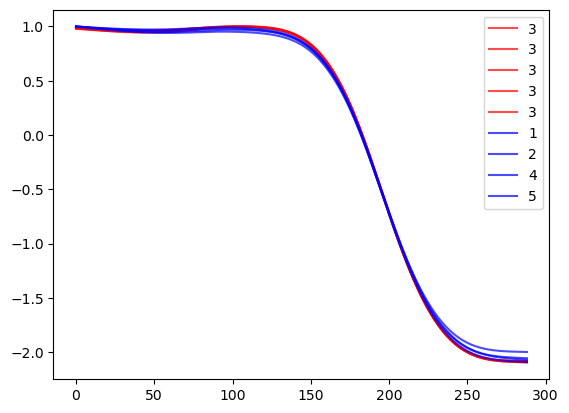

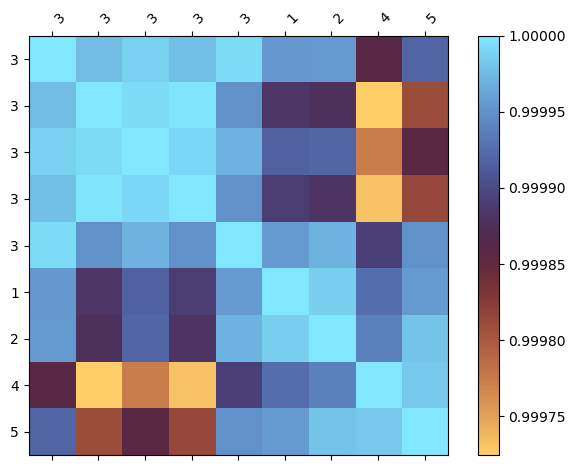

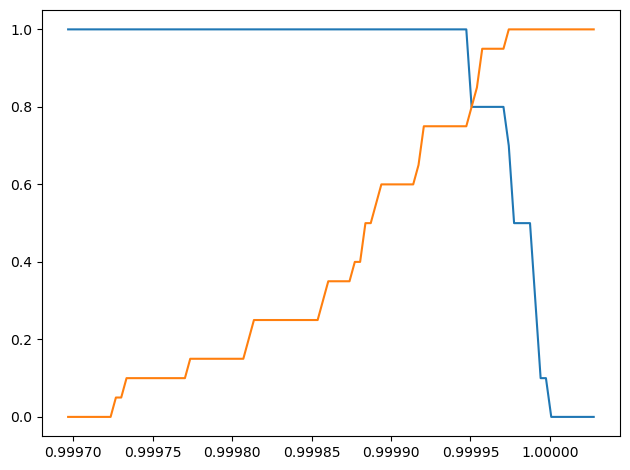

In [109]:
roi_map = {
    'tdp0604': (155, 445),
    'pi3hdx12211': (160, 450),
}
foo = list(roi_map.values())[0]
roi_n = foo[1] - foo[0]

def plot_covar(group_a, group_b, select_trace='open_fwd', select_channel='adc1', smooth=None, plot_cdf=False):
    group_a = sorted(group_a, key=lambda entry: entry['info']['serial'])
    group_b = sorted(group_b, key=lambda entry: entry['info']['serial'])
    all_traces = group_a + group_b
        
    d = np.zeros((len(all_traces), roi_n))
    labels = []
    for i, trace in enumerate(all_traces):
        trace_data = trace['data'][select_trace][select_channel]
        start, end = roi_map[trace['info']['chip']]
        trace_data = trace_data[start:end]

        if smooth is not None:
            t = np.linspace(0, 1, len(trace_data))
            spl = interpolate.make_smoothing_spline(t, trace_data, lam=smooth)
            trace_data = spl(t)
        
        d[i] = trace_data
        labels.append(str(trace['info']['serial']))
        
    
    # Normalize each curve such that its mean is at 0 and its min is at -1
    deltas = d[:,1:]
    deltas -= np.repeat(deltas.mean(axis=1)[:,np.newaxis], roi_n-1, axis=1)
    deltas /= np.repeat(deltas.max(axis=1)[:,np.newaxis], roi_n-1, axis=1)
    
    # Align all curves such that the trace starts where the trace crosses 0.5
    #roi_refined = round(np.mean(roi_n - 1 - np.argmax(deltas[:,::-1] > 0.5, axis=1))), roi_n
    #deltas = deltas[:,roi_refined[0]:roi_refined[1]]
    
    corr = np.corrcoef(deltas)
    
    fig, ax = plt.subplots()
    for i, (x, lab) in enumerate(zip(deltas, labels)):
        ax.plot(x, label=lab, color=('red' if i<len(group_a) else 'blue'), alpha=0.7)
    ax.legend()
    
    within_class = corr[:4, :4][np.triu_indices(4)]
    cross_class = corr[4:, :4].flatten()
    
    cdf = lambda x, mu, sigma: 1/2 * (1 + math.erf((x - mu) / (sigma * math.sqrt(2))))
    threshold = (np.mean(within_class) + np.mean(cross_class)) / 2
    print(f'Baseline threshold set at {threshold:.6f}')
    
    for name, data in [('Within', within_class), ('Cross', cross_class)]:
        print(f'{name} class: {np.mean(data):.3g}±{np.std(data):.3g} max: {np.max(data):.3g}')
    print(f'Baseline false negative probability: {cdf(threshold, np.mean(within_class), np.std(within_class)):.12f}')
    print(f'Baseline false positive probability: {1 - cdf(threshold, np.mean(cross_class), np.std(cross_class)):.12f}')
    
    #corr -= np.min(corr)
    #corr /= np.max(corr)
    
    #for i in range(len(corr[0])):
    #    corr[i, i] = math.nan
    
    fig, ax = plt.subplots()
    cax = ax.matshow(corr, interpolation='nearest', cmap='managua')
    fig.colorbar(cax)
    ax.set_xticks(list(range(len(labels))))
    ax.set_xticklabels(labels, rotation=45, ha='left')
    ax.set_yticks(list(range(len(labels))))
    ax.set_yticklabels(labels)
    fig.tight_layout()

    if plot_cdf:
        fig, ax = plt.subplots()
        all_classes = [0] * len(group_a) + [1] * len(group_b)
        min_corr = corr.min()
        max_corr = corr.max()
        d_corr = max_corr - min_corr
        x = np.linspace(min_corr - 0.1*d_corr, max_corr + 0.1 * d_corr, 100)

        correct_in_group = lambda thr: np.mean(corr[np.triu_indices(len(group_a), 1)] >= thr)
        correct_out_group = lambda thr: np.mean(corr[:len(group_a), len(group_a):] < thr)

        ax.plot(x, [correct_in_group(val) for val in x])
        ax.plot(x, [correct_out_group(val) for val in x])
        fig.tight_layout()
    #fig.savefig('../paper/manip_pearson_corr.pdf')

#group_a = [val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and key == 'M-SP-PITCH-V2-0001-0.4'][-5:]
#group_b = list({key: val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and re.match(r'M-SP-PITCH-V2-000[23456]-0\.4', key)}.values())

#group_a = [val for key, values in data.items() for val in values if val['info']['chip'] == 'tdp0604' and key == 'M-SP-PITCH-V2-0001-0.4'][-5:]
#group_b = list({key: val for key, values in data.items() for val in values if val['info']['chip'] == 'tdp0604' and re.match(r'M-SP-PITCH-V2-000[23456]-0\.4', key)}.values())
#plot_covar(group_a, group_b, select_trace='open_fwd', select_channel='adc1', smooth=None)

group_a = [val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and key == 'M-SP-PITCH-V2-0003-0.4'][-5:]
group_b = list({key: val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and re.match(r'M-SP-PITCH-V2-000[1245]-0\.4', key)}.values())
plot_covar(group_a, group_b, select_trace='open_fwd', smooth=1e-2, plot_cdf=True)

setting threshold for quantile 0.001
Baseline threshold set at 0.972987

Distribution parameters:
Within class: 0.979±0.00182 min: 0.975 max: 0.983
Cross class: 0.944±0.00617 min: 0.934 max: 0.96

Type 1 error (false alarm rate): 0.001000000000
Type 2 error (missed alarm rate): 0.000001501477
EER: 0.0 th: 0.9747796526628734


(<Figure size 300x300 with 2 Axes>,
 <Axes: >,
 <Figure size 300x150 with 1 Axes>,
 <Axes: >)

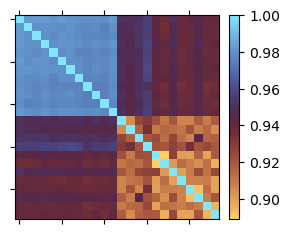

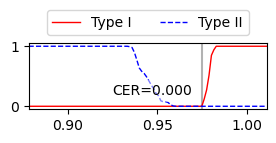

In [115]:
def plot_vector_covar(group_a, group_b, do_cal=False, vector_method='norm', distance_method='corr', smooth=None, plot_cdf=False, covar_out=None, cdf_out=None, fig_out=None, do_lines=False, batchlabels=None, figsize=(3, 3)):
    group_a = sorted(group_a, key=lambda entry: entry['info']['serial'])
    group_b = sorted(group_b, key=lambda entry: entry['info']['serial'])
    all_traces = group_a + group_b
    prints = []
    def print(*args):
        s = ' '.join(map(str, args))
        import builtins
        builtins.print(s)
        prints.append(s)

    if fig_out:
        covar_out = Path(f'../paper/fig_covar_{fig_out}.pdf')
        cdf_out = Path(f'../paper/fig_cdf_{fig_out}.pdf')
        results_out = Path(f'../paper/fig_results_{fig_out}.txt')
    else:
        results_out = None
        
    d = np.zeros((len(all_traces), 12, roi_n))
    labels = []
    for i, entry in enumerate(all_traces):
        start, end = roi_map[entry['info']['chip']]
        labels.append(entry['info']['serial'])
        for j, (term, direction, channel) in enumerate(itertools.product(['open', 'short', 'load'], ['fwd', 'flip'], ['adc1', 'adc2'])):
            trace_data = np.array(entry['data'][f'{term}_{direction}'][channel])
            if do_cal:
                trace_data -= np.array(entry['data']['cal'][channel])
                
            if smooth is not None:
                t = np.linspace(0, 1, len(trace_data))
                spl = interpolate.make_smoothing_spline(t, trace_data, lam=smooth)
                trace_data = spl(t)
            
            d[i, j] = trace_data[start:end]
    
    # Normalize each curve such that its mean is at 0 and its min is at -1
    deltas = d[:,:,1:]
    deltas -= np.repeat(deltas.mean(axis=2)[:,:,np.newaxis], roi_n-1, axis=2)
    deltas /= np.repeat(deltas.max(axis=2)[:,:,np.newaxis], roi_n-1, axis=2)
    
    # Align all curves such that the trace starts where the trace crosses 0.5
    #roi_refined = round(np.mean(roi_n - 1 - np.argmax(deltas[:,::-1] > 0.5, axis=1))), roi_n
    #deltas = deltas[:,roi_refined[0]:roi_refined[1]]

    corr = np.zeros((12, len(all_traces), len(all_traces)))
    for i in range(12):
        if distance_method == 'corr':
            corr[i] = np.corrcoef(deltas[:,i,:])
        elif distance_method == 'max':
            for k, l in itertools.product(range(len(all_traces)), repeat=2):
                corr[i, k, l] = 1 - np.abs(deltas[k,i,:] - deltas[l,i,:]).max()
        else:
            raise ValueError(f'invalid distance_method {distance_method!r}')

    if vector_method == 'norm':
        corr = np.sqrt(np.mean(np.square(corr), axis=0))
    elif vector_method == 'min':
        corr = np.min(corr, axis=0)
    else:
        raise ValueError(f'invalid vector_method {vector_method!r}')
    
    within_class = corr[:len(group_a), :len(group_a)][np.triu_indices(len(group_a), 1)]
    cross_class = corr[len(group_a):, :len(group_a)].flatten()
    
    cdf = lambda x, mu, sigma: 1/2 * (1 + math.erf((x - mu) / (sigma * math.sqrt(2))))
    quantile = lambda x, mu, sigma: mu + sigma * np.sqrt(2) * scipy.special.erfinv(2*x-1)
    #threshold = (np.mean(within_class) + np.mean(cross_class)) / 2
    #threshold = np.mean(within_class) -2*np.std(within_class)
    #threshold = (np.min(within_class) + np.max(cross_class)) / 2
    baseline_quantile = 0.001
    print(f'setting threshold for quantile {baseline_quantile}')
    threshold = quantile(baseline_quantile, np.mean(within_class), np.std(within_class))
    print(f'Baseline threshold set at {threshold:.6f}')

    print()
    print('Distribution parameters:')
    for name, data in [('Within', within_class), ('Cross', cross_class)]:
        print(f'{name} class: {np.mean(data):.3g}±{np.std(data):.3g} min: {np.min(data):.3g} max: {np.max(data):.3g}')
    print()
    print(f'Type 1 error (false alarm rate): {cdf(threshold, np.mean(within_class), np.std(within_class)):.12f}')
    print(f'Type 2 error (missed alarm rate): {1 - cdf(threshold, np.mean(cross_class), np.std(cross_class)):.12f}')
    
    #corr -= np.min(corr)
    #corr /= np.max(corr)
    
    #for i in range(len(corr[0])):
    #    corr[i, i] = math.nan
    
    fig, ax = plt.subplots(figsize=figsize)
    corr_ax = ax.matshow(corr, interpolation='none', cmap='managua')
    if batchlabels:
        ticks, labels = batchlabels
        ax.set_xticks(ticks)
        ax.set_xticklabels(labels, rotation=45, ha='left')
        ax.set_yticks(ticks)
        ax.set_yticklabels(labels, rotation=0)
    else:
        ax.set_xticklabels([])
        ax.set_yticklabels([])
    
    # https://stackoverflow.com/questions/18195758/set-matplotlib-colorbar-size-to-match-graph                   
    from mpl_toolkits.axes_grid1 import make_axes_locatable, axes_size
    divider = make_axes_locatable(ax)
    aspect = 20
    pad_fraction = 1
    width = axes_size.AxesY(ax, aspect=1./aspect)
    pad = axes_size.Fraction(pad_fraction, width)
    cax = divider.append_axes("right", size=width, pad=pad)
    plt.colorbar(corr_ax, cax=cax)

    #fig.colorbar(cax)
    #ax.set_xticks(list(range(len(labels))))
    #ax.set_xticklabels(labels, rotation=45, ha='left')
    #ax.set_yticks(list(range(len(labels))))
    #ax.set_yticklabels(labels)
    if do_lines:
        ax.plot([-0.5, len(all_traces)-0.5], [len(group_a)-0.5, len(group_a)-0.5], '-', color='white', linewidth=1)
        ax.plot([len(group_a)-0.5, len(group_a)-0.5], [-0.5, len(all_traces)-0.5], '-', color='white', linewidth=1)
    fig.tight_layout()
    if covar_out:
        fig.savefig(covar_out)

    fig_c, ax_c = fig, ax
    if plot_cdf:
        fig, ax = plt.subplots(figsize=(3, 1.5))
        all_classes = [0] * len(group_a) + [1] * len(group_b)
        min_corr = corr.min()
        max_corr = corr.max()
        d_corr = max_corr - min_corr
        x = np.linspace(min_corr - 0.1*d_corr, max_corr + 0.1 * d_corr, 100)

        correct_in_group = lambda thr: np.mean(corr[np.triu_indices(len(group_a), 1)] < thr)
        correct_out_group = lambda thr: np.mean(corr[:len(group_a), len(group_a):] >= thr)

        cdf_in_group = [correct_in_group(val) for val in x]
        cdf_out_group = [correct_out_group(val) for val in x]

        for x1, x2, a, b, c, d in zip(x, x[1:], cdf_in_group, cdf_in_group[1:], cdf_out_group, cdf_out_group[1:]):
            if a <= c and b >= d:
                # lines cross
                if a == b == c == d:
                    eer = 0.0
                    eer_th = x2
                else:
                    eer_th = (c - a) / (b + c - a - d)
                    eer = eer_th * (d - c) + c
                    eer_th = eer_th*(x2 - x1) + x1
        print(f'EER: {eer} th: {eer_th}')
        #ax.axhline(eer)
        ax.axvline(eer_th, color='black', alpha=0.3, zorder=-2)
        offx, offy = 10, 0
        hora = 'left'
        if eer > 0.85:
            offy -= 15
        elif eer < 0.15:
            offy += 15
        if (eer_th - min_corr) / (max_corr - min_corr) > 0.7:
            offx = -offx
            hora = 'right'
        ax.annotate(f'CER={eer:.3f}', (eer_th, eer), (offx, offy), textcoords='offset pixels', verticalalignment='center', horizontalalignment=hora,
                   bbox={'boxstyle': 'square,pad=0.3', 'fc': '#ffffff80', 'ec': None, 'lw': 0})
        
        ax.plot(x, cdf_in_group, color='red', linewidth=1, linestyle='-', label='Type I')
        ax.plot(x, cdf_out_group, color='blue', linewidth=1, linestyle='--', label='Type II')
        #ax.legend(loc='best')
        # Put legend above plot, from:
        # https://stackoverflow.com/questions/4700614/how-to-put-the-legend-outside-the-plot
        fig.tight_layout()
        box = ax.get_position()
        ax.set_position([box.x0, box.y0, box.width, box.height - 0.2])
        # Put a legend below current axis
        ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.02), ncol=2)

        ax.set_xlim((min(x), max(x)))
        if cdf_out:
            fig.savefig(cdf_out)
    else:
        eer = '<not calculated>'
        fig, ax = None, None

    if results_out:
        results_out.write_text('\n'.join([
            f'Results calculated from plots {covar_out.name} / {cdf_out.name if plot_cdf else '<none>'} on {datetime.datetime.now().isoformat()}',
            f'',
            *prints
        ]))

    return fig_c, ax_c, fig, ax
    #fig.savefig('../paper/manip_pearson_corr.pdf')

#group_a = [val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and key == 'M-SP-PITCH-V2-0003-0.4'][-5:]
#group_b = list({key: val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and re.match(r'M-SP-PITCH-V2-000[1245]-0\.4', key)}.values())
#plot_vector_covar(group_a, group_b, distance_method='corr', smooth=None)

group_baseline = [value for value in data['M-SP-PITCH-V2-0010-0.3'] if value['info']['meta'] == 'probe-interleave-25-07-02-01-p0.3'][:12]
group_probed = [value for entries in data.values() for value in entries if value['info']['meta'] == 'probe-interleave-25-07-02-01-p0.3' and 'probe_points' in value['info']['mods']]
plot_vector_covar(group_baseline, group_probed, vector_method='norm', distance_method='corr', plot_cdf=True)

## Can we distinguish one specimen from other specimens with the same layout?

setting threshold for quantile 0.001
Baseline threshold set at 0.968471

Distribution parameters:
Within class: 0.978±0.00301 min: 0.974 max: 0.982
Cross class: 0.972±0.00323 min: 0.964 max: 0.976

Type 1 error (false alarm rate): 0.001000000000
Type 2 error (missed alarm rate): 0.854339164110
EER: 0.23333333333333334 th: 0.9742671141482576


(<Figure size 300x300 with 2 Axes>,
 <Axes: >,
 <Figure size 300x150 with 1 Axes>,
 <Axes: >)

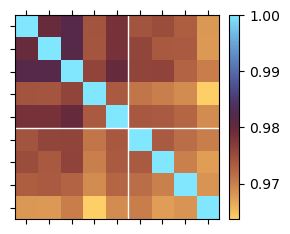

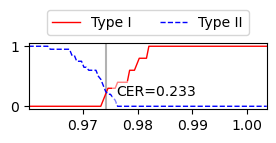

In [11]:
group_a = [val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and key == 'M-SP-PITCH-V2-0005-0.4'][-5:]
group_b = list({key: val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and re.match(r'M-SP-PITCH-V2-000[1234]-0\.4', key)}.values())
plot_vector_covar(group_a, group_b, plot_cdf=True, fig_out='distinguish_copies', do_lines=True)

## Can we distinguish mesh layout variants?

Compare measurements of five specimens of the base layout against measurements of each of the four alternate layouts.

setting threshold for quantile 0.001
Baseline threshold set at 0.106885

Distribution parameters:
Within class: 0.318±0.0684 min: 0.221 max: 0.438
Cross class: -0.247±0.369 min: -1.01 max: 0.122

Type 1 error (false alarm rate): 0.001000000000
Type 2 error (missed alarm rate): 0.168686174058
EER: 0.0 th: 0.2132482612886455


(<Figure size 300x300 with 2 Axes>,
 <Axes: >,
 <Figure size 300x150 with 1 Axes>,
 <Axes: >)

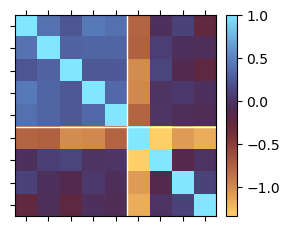

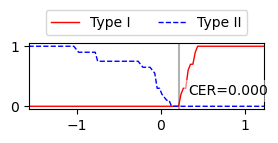

In [12]:
group_a = list({key: val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and re.match(r'M-SP-PITCH-V2-000[12345]-0\.4', key)}.values())
group_b = list({val['info']['mesh_layout']: val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and 'ALT' in val['info']['mesh_layout']}.values())
plot_vector_covar(group_a, group_b, vector_method='min', distance_method='max', fig_out='distinguish_layouts', plot_cdf=True, do_lines=True)

#### Same measurement, but show TPD0604 data 

setting threshold for quantile 0.001
Baseline threshold set at 0.995828

Distribution parameters:
Within class: 0.997±0.00035 min: 0.996 max: 0.997
Cross class: 0.98±0.0243 min: 0.935 max: 0.995

Type 1 error (false alarm rate): 0.001000000000
Type 2 error (missed alarm rate): 0.252693473932


(<Figure size 300x300 with 2 Axes>, <Axes: >, None, None)

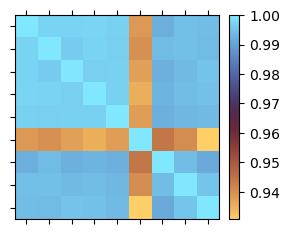

In [13]:
group_a = list({key: val for key, values in data.items() for val in values if val['info']['chip'] == 'tdp0604' and re.match(r'M-SP-PITCH-V2-000[12345]-0\.4', key)}.values())
group_b = list({val['info']['mesh_layout']: val for key, values in data.items() for val in values if val['info']['chip'] == 'tdp0604' and 'ALT' in val['info']['mesh_layout']}.values())
plot_vector_covar(group_a, group_b, do_cal=False)

## Preliminary attack measurements

setting threshold for quantile 0.001
Baseline threshold set at 0.973311

Distribution parameters:
Within class: 0.981±0.00258 min: 0.976 max: 0.985
Cross class: 0.561±0.0492 min: 0.468 max: 0.659

Type 1 error (false alarm rate): 0.001000000000
Type 2 error (missed alarm rate): 0.000000000000


(<Figure size 300x300 with 2 Axes>, <Axes: >, None, None)

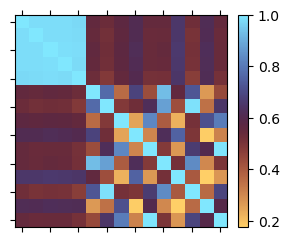

In [14]:
plot_vector_covar(mod_baseline[0.3], mod_modified['short_across_traces', 0.3])

setting threshold for quantile 0.001
Baseline threshold set at 0.973311

Distribution parameters:
Within class: 0.981±0.00258 min: 0.976 max: 0.985
Cross class: 0.43±0.073 min: 0.321 max: 0.616

Type 1 error (false alarm rate): 0.001000000000
Type 2 error (missed alarm rate): 0.000000000000


(<Figure size 300x300 with 2 Axes>, <Axes: >, None, None)

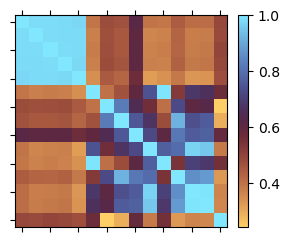

In [15]:
plot_vector_covar(mod_baseline[0.3], mod_modified['short_across_traces', 0.4])

setting threshold for quantile 0.001
Baseline threshold set at 0.973311

Distribution parameters:
Within class: 0.981±0.00258 min: 0.976 max: 0.985
Cross class: 0.317±0.0446 min: 0.225 max: 0.373

Type 1 error (false alarm rate): 0.001000000000
Type 2 error (missed alarm rate): 0.000000000000


(<Figure size 300x300 with 2 Axes>, <Axes: >, None, None)

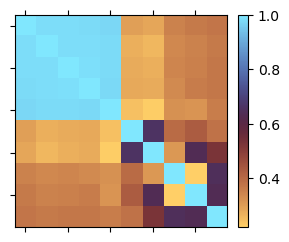

In [16]:
plot_vector_covar(mod_baseline[0.3], mod_modified['short_across_traces', 0.6])

setting threshold for quantile 0.001
Baseline threshold set at 0.973311

Distribution parameters:
Within class: 0.981±0.00258 min: 0.976 max: 0.985
Cross class: 0.19±0.0354 min: 0.15 max: 0.264

Type 1 error (false alarm rate): 0.001000000000
Type 2 error (missed alarm rate): 0.000000000000


(<Figure size 300x300 with 2 Axes>, <Axes: >, None, None)

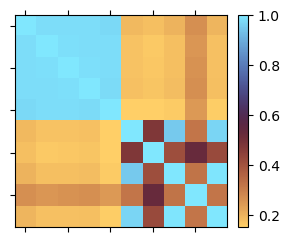

In [17]:
plot_vector_covar(mod_baseline[0.3], mod_modified['short_across_traces', 1.0])

setting threshold for quantile 0.001
Baseline threshold set at 0.973311

Distribution parameters:
Within class: 0.981±0.00258 min: 0.976 max: 0.985
Cross class: 0.697±0.0452 min: 0.634 max: 0.766

Type 1 error (false alarm rate): 0.001000000000
Type 2 error (missed alarm rate): 0.000000000477


(<Figure size 300x300 with 2 Axes>, <Axes: >, None, None)

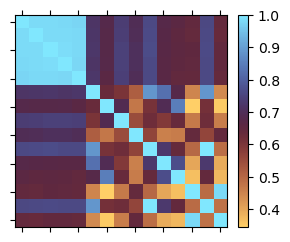

In [18]:
plot_vector_covar(mod_baseline[0.3], mod_modified['open', 0.3])

setting threshold for quantile 0.001
Baseline threshold set at 0.973311

Distribution parameters:
Within class: 0.981±0.00258 min: 0.976 max: 0.985
Cross class: 0.553±0.0426 min: 0.496 max: 0.653

Type 1 error (false alarm rate): 0.001000000000
Type 2 error (missed alarm rate): 0.000000000000


(<Figure size 300x300 with 2 Axes>, <Axes: >, None, None)

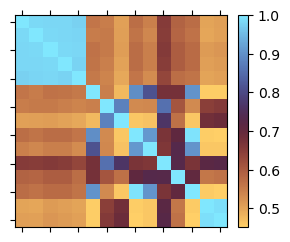

In [19]:
plot_vector_covar(mod_baseline[0.3], mod_modified['open', 0.4])

setting threshold for quantile 0.001
Baseline threshold set at 0.973311

Distribution parameters:
Within class: 0.981±0.00258 min: 0.976 max: 0.985
Cross class: 0.379±0.0899 min: 0.279 max: 0.549

Type 1 error (false alarm rate): 0.001000000000
Type 2 error (missed alarm rate): 0.000000000020


(<Figure size 300x300 with 2 Axes>, <Axes: >, None, None)

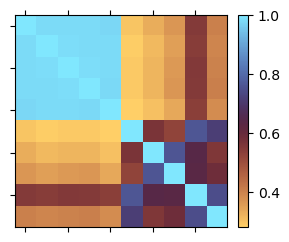

In [20]:
plot_vector_covar(mod_baseline[0.3], mod_modified['open', 0.6])

setting threshold for quantile 0.001
Baseline threshold set at 0.973311

Distribution parameters:
Within class: 0.981±0.00258 min: 0.976 max: 0.985
Cross class: 0.268±0.0867 min: 0.183 max: 0.454

Type 1 error (false alarm rate): 0.001000000000
Type 2 error (missed alarm rate): 0.000000000000


(<Figure size 300x300 with 2 Axes>, <Axes: >, None, None)

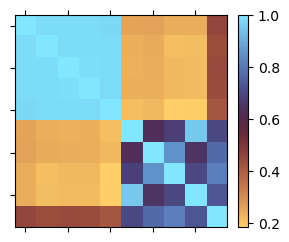

In [21]:
plot_vector_covar(mod_baseline[0.3], mod_modified['open', 1.0])

setting threshold for quantile 0.001
Baseline threshold set at 0.997260

Distribution parameters:
Within class: 0.999±0.00057 min: 0.998 max: 1
Cross class: 0.937±0.0917 min: 0.736 max: 0.999

Type 1 error (false alarm rate): 0.001000000000
Type 2 error (missed alarm rate): 0.255829819568


(<Figure size 300x300 with 2 Axes>, <Axes: >, None, None)

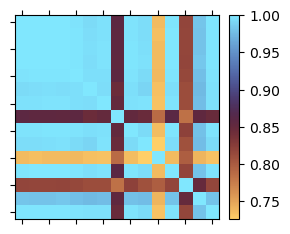

In [22]:
plot_vector_covar(mod_baseline[0.3], mod_modified['short_within_trace', 0.3], distance_method='corr', vector_method='norm', smooth=1e-5)

Baseline threshold set at 0.933052
Within class: 0.999±0.000772 max: 1
Cross class: 0.867±0.21 max: 0.999
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.376261529102


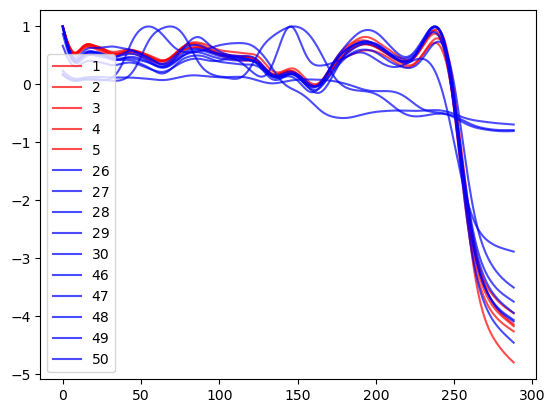

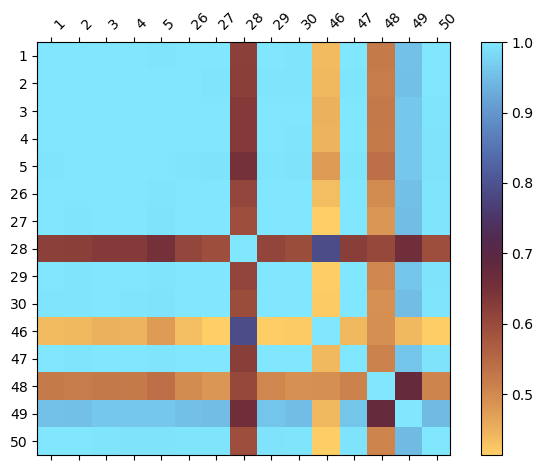

In [23]:
plot_covar(mod_baseline[0.3], mod_modified['short_within_trace', 0.3], select_trace='open_fwd', select_channel='adc1', smooth=1e-5)

setting threshold for quantile 0.001
Baseline threshold set at 0.973311

Distribution parameters:
Within class: 0.981±0.00258 min: 0.976 max: 0.985
Cross class: 0.633±0.0626 min: 0.508 max: 0.704

Type 1 error (false alarm rate): 0.001000000000
Type 2 error (missed alarm rate): 0.000000026261


(<Figure size 300x300 with 2 Axes>, <Axes: >, None, None)

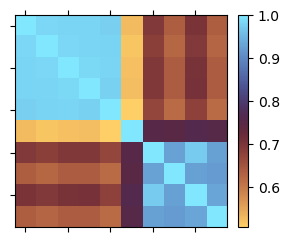

In [24]:
plot_vector_covar(mod_baseline[0.3], mod_modified['short_within_trace', 0.4])

setting threshold for quantile 0.001
Baseline threshold set at 0.973311

Distribution parameters:
Within class: 0.981±0.00258 min: 0.976 max: 0.985
Cross class: 0.346±0.00834 min: 0.325 max: 0.354

Type 1 error (false alarm rate): 0.001000000000
Type 2 error (missed alarm rate): 0.000000000000


(<Figure size 300x300 with 2 Axes>, <Axes: >, None, None)

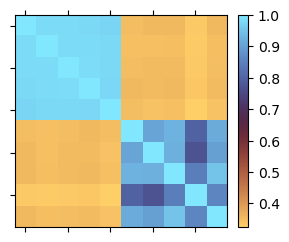

In [25]:
plot_vector_covar(mod_baseline[0.3], mod_modified['short_within_trace', 0.6])

setting threshold for quantile 0.001
Baseline threshold set at 0.973311

Distribution parameters:
Within class: 0.981±0.00258 min: 0.976 max: 0.985
Cross class: 0.261±0.0215 min: 0.22 max: 0.304

Type 1 error (false alarm rate): 0.001000000000
Type 2 error (missed alarm rate): 0.000000000000


(<Figure size 300x300 with 2 Axes>, <Axes: >, None, None)

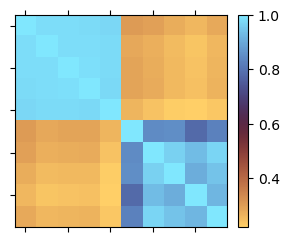

In [26]:
plot_vector_covar(mod_baseline[0.3], mod_modified['short_within_trace', 1.0])

## Can we detect a short within the same trace?

setting threshold for quantile 0.001
Baseline threshold set at 0.974230

Distribution parameters:
Within class: 0.98±0.00188 min: 0.975 max: 0.983
Cross class: 0.886±0.106 min: 0.699 max: 0.982

Type 1 error (false alarm rate): 0.001000000000
Type 2 error (missed alarm rate): 0.202356316486
setting threshold for quantile 0.001
Baseline threshold set at 0.872507

Distribution parameters:
Within class: 0.907±0.0112 min: 0.873 max: 0.931
Cross class: 0.402±0.505 min: -0.462 max: 0.914

Type 1 error (false alarm rate): 0.001000000000
Type 2 error (missed alarm rate): 0.176007873311
setting threshold for quantile 0.001
Baseline threshold set at 0.593452

Distribution parameters:
Within class: 0.7±0.0346 min: 0.617 max: 0.761
Cross class: 0.737±0.142 min: 0.54 max: 1.14

Type 1 error (false alarm rate): 0.001000000000
Type 2 error (missed alarm rate): 0.844643997379
setting threshold for quantile 0.001
Baseline threshold set at -0.047185

Distribution parameters:
Within class: 0.306±0.114 mi

(<Figure size 300x300 with 2 Axes>,
 <Axes: >,
 <Figure size 300x150 with 1 Axes>,
 <Axes: >)

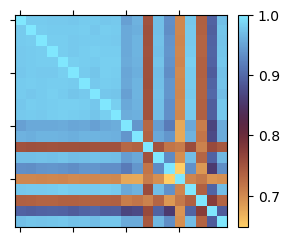

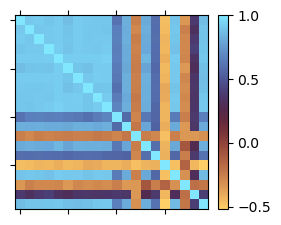

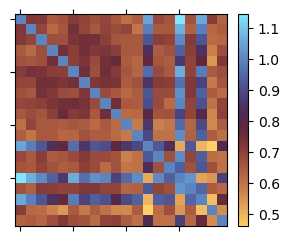

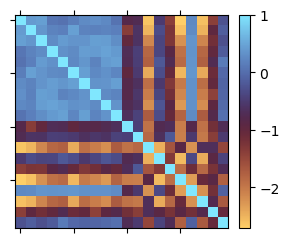

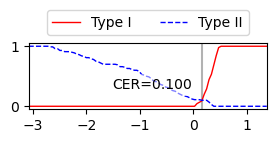

In [27]:
entries = [value for entry in data.values() for value in entry if value['info']['meta'] == 'interleaved-25-07-02-01-p0.3']
group_baseline = [value for value in entries if not value['info']['mods']]
group_modified = [value for value in entries if value['info']['mods']]

smooth = None
plot_vector_covar(group_baseline, group_modified, vector_method='norm', distance_method='corr', smooth=smooth)
plot_vector_covar(group_baseline, group_modified, vector_method='min', distance_method='corr', smooth=smooth)
plot_vector_covar(group_baseline, group_modified, vector_method='norm', distance_method='max', smooth=smooth)
plot_vector_covar(group_baseline, group_modified, vector_method='min', distance_method='max', smooth=smooth, plot_cdf=True)

In [ ]:
entries = [value for entry in data.values() for value in entry if value['info']['meta'] == 'interleaved-25-07-02-02-p0.3']
group_baseline = [value for value in entries if not value['info']['mods']]
group_modified = [value for value in entries if value['info']['mods']]
print([value['info']['mods'] for value in group_modified])

smooth = 1e-7
plot_vector_covar(group_baseline, group_modified, vector_method='norm', distance_method='corr', smooth=smooth)
plot_vector_covar(group_baseline, group_modified, vector_method='min', distance_method='corr', smooth=smooth)
plot_vector_covar(group_baseline, group_modified, vector_method='norm', distance_method='max', smooth=smooth)
plot_vector_covar(group_baseline, group_modified, vector_method='min', distance_method='max', smooth=smooth, plot_cdf=True, fig_out='short_within_0.3_min_max', do_lines=True)

[['short_within_trace'], ['short_within_trace'], ['short_within_trace'], ['short_within_trace'], ['short_within_trace'], ['short_within_trace'], ['short_within_trace'], ['short_within_trace'], ['short_within_trace'], ['short_within_trace']]
setting threshold for quantile 0.001
Baseline threshold set at 0.995575

Distribution parameters:
Within class: 0.998±0.000902 min: 0.995 max: 0.999
Cross class: 0.931±0.0892 min: 0.789 max: 0.999

Type 1 error (false alarm rate): 0.001000000000
Type 2 error (missed alarm rate): 0.233499797763
setting threshold for quantile 0.001
Baseline threshold set at 0.988903

Distribution parameters:
Within class: 0.996±0.00231 min: 0.988 max: 0.999
Cross class: 0.745±0.353 min: -0.0688 max: 0.997

Type 1 error (false alarm rate): 0.001000000000
Type 2 error (missed alarm rate): 0.244707237254
setting threshold for quantile 0.001
Baseline threshold set at 0.876642

Distribution parameters:
Within class: 0.936±0.0191 min: 0.899 max: 0.968
Cross class: 0.768±0.1

tdp0604 tdp0604
[['short_within_trace'], ['short_within_trace'], ['short_within_trace'], ['short_within_trace'], ['short_within_trace'], ['short_within_trace'], ['short_within_trace'], ['short_within_trace'], ['short_within_trace'], ['short_within_trace']]
setting threshold for quantile 0.001
Baseline threshold set at 0.994850

Distribution parameters:
Within class: 0.996±0.000496 min: 0.995 max: 0.998
Cross class: 0.925±0.0896 min: 0.783 max: 0.996

Type 1 error (false alarm rate): 0.001000000000
Type 2 error (missed alarm rate): 0.218796775409
setting threshold for quantile 0.001
Baseline threshold set at 0.982344

Distribution parameters:
Within class: 0.989±0.00226 min: 0.985 max: 0.994
Cross class: 0.725±0.358 min: -0.0808 max: 0.991

Type 1 error (false alarm rate): 0.001000000000
Type 2 error (missed alarm rate): 0.235755269216
setting threshold for quantile 0.001
Baseline threshold set at 0.879213

Distribution parameters:
Within class: 0.903±0.00772 min: 0.879 max: 0.921
Cross

(<Figure size 300x300 with 2 Axes>, <Axes: >, None, None)

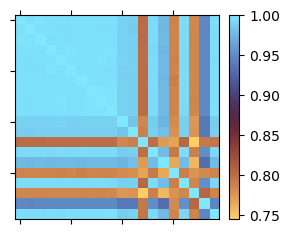

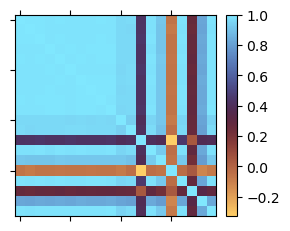

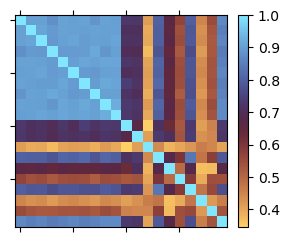

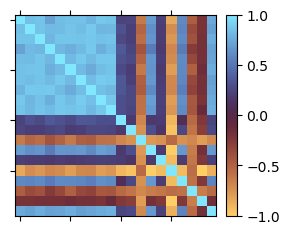

In [29]:
entries = [value for entry in data.values() for value in entry if value['info']['meta'] == 'interleaved-25-07-02-02-p0.3']
entries_repeat = [value for entry in data.values() for value in entry if value['info']['meta'] == 'baseline-repeat-25-07-02-01-p0.3']
print(entries[0]['info']['chip'], entries_repeat[0]['info']['chip'])
group_baseline = [value for value in entries_repeat if not value['info']['mods']][:10]
group_modified = [value for value in entries if value['info']['mods']]
print([value['info']['mods'] for value in group_modified])

smooth = None
plot_vector_covar(group_baseline, group_modified, vector_method='norm', distance_method='corr', smooth=smooth)
plot_vector_covar(group_baseline, group_modified, vector_method='min', distance_method='corr', smooth=smooth)
plot_vector_covar(group_baseline, group_modified, vector_method='norm', distance_method='max', smooth=smooth) 
plot_vector_covar(group_baseline, group_modified, vector_method='min', distance_method='max', smooth=smooth)

tdp0604 tdp0604
[['short_within_trace'], ['short_within_trace'], ['short_within_trace'], ['short_within_trace'], ['short_within_trace'], ['short_within_trace'], ['short_within_trace'], ['short_within_trace'], ['short_within_trace'], ['short_within_trace']]
setting threshold for quantile 0.001
Baseline threshold set at 0.994850

Distribution parameters:
Within class: 0.996±0.000496 min: 0.995 max: 0.998
Cross class: 0.925±0.0896 min: 0.783 max: 0.996

Type 1 error (false alarm rate): 0.001000000000
Type 2 error (missed alarm rate): 0.218796775409
EER: 0.08256880733944955 th: 0.9948339629072368
setting threshold for quantile 0.001
Baseline threshold set at 0.723555

Distribution parameters:
Within class: 0.834±0.0358 min: 0.717 max: 0.886
Cross class: 0.0832±0.499 min: -0.843 max: 0.775

Type 1 error (false alarm rate): 0.001000000000
Type 2 error (missed alarm rate): 0.099837794942
EER: 0.034042553191489355 th: 0.7515290358358554


(<Figure size 300x300 with 2 Axes>,
 <Axes: >,
 <Figure size 300x150 with 1 Axes>,
 <Axes: >)

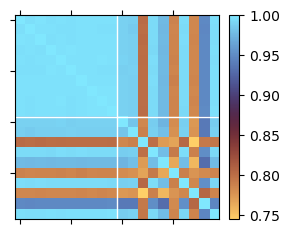

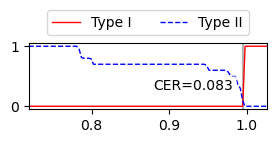

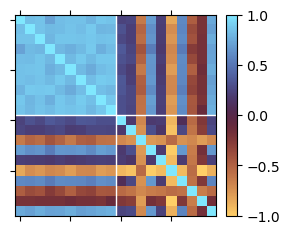

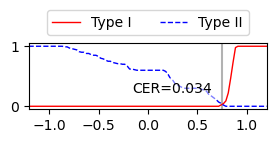

In [30]:
entries = [value for entry in data.values() for value in entry if value['info']['meta'] == 'interleaved-25-07-02-02-p0.3']
entries_repeat = [value for entry in data.values() for value in entry if value['info']['meta'] == 'baseline-repeat-25-07-02-01-p0.3']
print(entries[0]['info']['chip'], entries_repeat[0]['info']['chip'])
group_baseline = [value for value in entries_repeat if not value['info']['mods']][:10]
group_modified = [value for value in entries if value['info']['mods']]
print([value['info']['mods'] for value in group_modified])

smooth = None
plot_vector_covar(group_baseline, group_modified, vector_method='norm', distance_method='corr', smooth=smooth, plot_cdf=True, do_lines=True)
plot_vector_covar(group_baseline, group_modified, vector_method='min', distance_method='max', smooth=smooth, plot_cdf=True, do_lines=True)

## Can we detect when a trace is probed using an oscilloscope probe?

* probed with rigol PVP3150 probe, connected to running Rigol DS1054Z scope. probe grounded using ground clip to mesh specimen board ground area
* baseline also measured with ground clip connected to exclude grounding as the measured effect

### Pitch 0.3 mm

pi3hdx12211
setting threshold for quantile 0.001
Baseline threshold set at 0.972987

Distribution parameters:
Within class: 0.979±0.00182 min: 0.975 max: 0.983
Cross class: 0.944±0.00617 min: 0.934 max: 0.96

Type 1 error (false alarm rate): 0.001000000000
Type 2 error (missed alarm rate): 0.000001501477
EER: 0.0 th: 0.9747796526628734


(<Figure size 300x300 with 2 Axes>,
 <Axes: >,
 <Figure size 300x150 with 1 Axes>,
 <Axes: >)

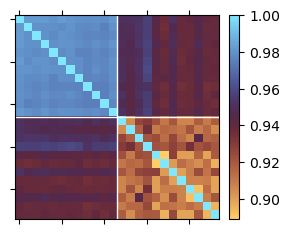

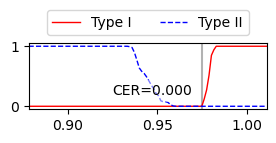

In [31]:

group_baseline = [value for value in data['M-SP-PITCH-V2-0010-0.3'] if value['info']['meta'] == 'probe-interleave-25-07-02-01-p0.3'][:12]
group_probed = [value for entries in data.values() for value in entries if value['info']['meta'] == 'probe-interleave-25-07-02-01-p0.3' and 'probe_points' in value['info']['mods']]
print(group_baseline[0]['info']['chip'])

smooth = None
plot_vector_covar(group_baseline, group_probed, vector_method='norm', distance_method='corr', smooth=smooth, plot_cdf=True, fig_out='probe_0.3', do_lines=True)

### Pitch 0.4 mm

setting threshold for quantile 0.001
Baseline threshold set at 0.963759

Distribution parameters:
Within class: 0.972±0.00261 min: 0.965 max: 0.976
Cross class: 0.93±0.00368 min: 0.919 max: 0.937

Type 1 error (false alarm rate): 0.001000000000
Type 2 error (missed alarm rate): 0.000000000000
EER: 0.0 th: 0.9640827677501544


(<Figure size 300x300 with 2 Axes>,
 <Axes: >,
 <Figure size 300x150 with 1 Axes>,
 <Axes: >)

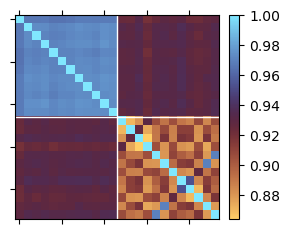

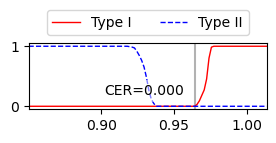

In [32]:
group_baseline = [value for value in data['M-SP-PITCH-V2-0010-0.4'] if value['info']['meta'] == 'probe-interleave-25-07-02-01-p0.4'][:12]
group_probed = [value for entries in data.values() for value in entries if value['info']['meta'] == 'probe-interleave-25-07-02-01-p0.4' and 'probe_points' in value['info']['mods']]

smooth = None
plot_vector_covar(group_baseline, group_probed, vector_method='norm', distance_method='corr', smooth=smooth, plot_cdf=True, fig_out='probe_0.4', do_lines=True)

## Can we detect when the mesh is touched?

setting threshold for quantile 0.001
Baseline threshold set at 0.981066

Distribution parameters:
Within class: 0.984±0.00094 min: 0.982 max: 0.986
Cross class: 0.924±0.0132 min: 0.89 max: 0.948

Type 1 error (false alarm rate): 0.001000000000
Type 2 error (missed alarm rate): 0.000007289617
EER: 0.0 th: 0.9811027642073021


(<Figure size 300x300 with 2 Axes>,
 <Axes: >,
 <Figure size 300x150 with 1 Axes>,
 <Axes: >)

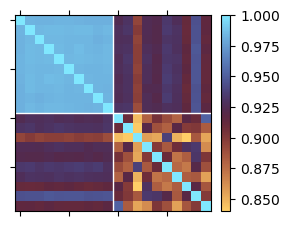

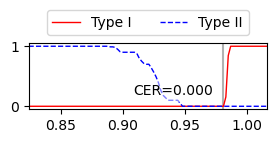

In [33]:
group_baseline = [value for value in data['M-SP-PITCH-V2-0004-0.3'] if value['info']['meta'] == 'touch-interleave-touch-serial-5-25-07-02-01-p0.3'][:10]
group_touch = [value for value in data['M-SP-PITCH-V2-0005-0.3'] if value['info']['meta'] == 'touch-interleave-touch-serial-5-25-07-02-01-p0.3'][:10]

smooth = None
plot_vector_covar(group_baseline, group_touch, vector_method='norm', distance_method='corr', smooth=smooth, plot_cdf=True, fig_out='touch_mesh', do_lines=True)

## Is our circuit sensitive to grounding? Would we detect if the mesh ground is touched?

setting threshold for quantile 0.001
Baseline threshold set at 0.981497

Distribution parameters:
Within class: 0.984±0.000888 min: 0.982 max: 0.986
Cross class: 0.982±0.000887 min: 0.981 max: 0.985

Type 1 error (false alarm rate): 0.001000000000
Type 2 error (missed alarm rate): 0.833350961269
EER: 0.1676190476190476 th: 0.9831607423686642


(<Figure size 300x300 with 2 Axes>,
 <Axes: >,
 <Figure size 300x150 with 1 Axes>,
 <Axes: >)

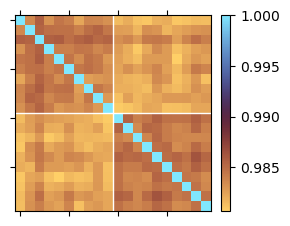

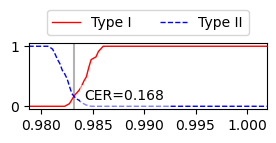

In [34]:
group_baseline = [value for value in data['M-SP-PITCH-V2-0004-0.3'] if value['info']['meta'] == 'touch-ground-interleave-touch-serial-5-25-07-02-01-p0.3'][:10]
group_touch = [value for value in data['M-SP-PITCH-V2-0005-0.3'] if value['info']['meta'] == 'touch-ground-interleave-touch-serial-5-25-07-02-01-p0.3'][:10]

smooth = None
plot_vector_covar(group_baseline, group_touch, vector_method='norm', distance_method='corr', smooth=smooth, plot_cdf=True, fig_out='touch_ground', do_lines=True)

## Compare the two above cases.

setting threshold for quantile 0.001
Baseline threshold set at 0.978979

Distribution parameters:
Within class: 0.983±0.00136 min: 0.98 max: 0.986
Cross class: 0.926±0.0136 min: 0.89 max: 0.953

Type 1 error (false alarm rate): 0.001000000000
Type 2 error (missed alarm rate): 0.000042953295
EER: 0.0 th: 0.9791645861772819


(<Figure size 400x400 with 2 Axes>,
 <Axes: >,
 <Figure size 300x150 with 1 Axes>,
 <Axes: >)

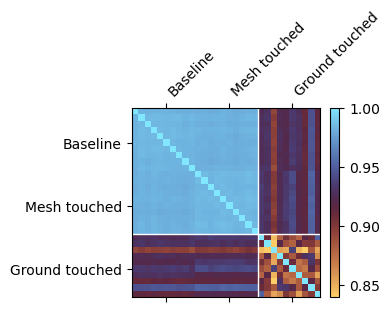

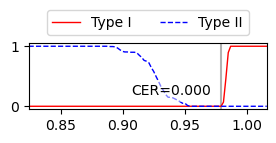

In [35]:
# touch group: touched with one or more fingers directly to the mesh surface
# ground group: ground plane of mesh specimen board firmly touched, but mesh not touched directly
group_baseline = [value for value in data['M-SP-PITCH-V2-0004-0.3'] if value['info']['meta'] == 'touch-interleave-touch-serial-5-25-07-02-01-p0.3'][:10]
group_touch_ground = [value for value in data['M-SP-PITCH-V2-0005-0.3'] if value['info']['meta'] == 'touch-ground-interleave-touch-serial-5-25-07-02-01-p0.3'][:10]
group_touch = [value for value in data['M-SP-PITCH-V2-0005-0.3'] if value['info']['meta'] == 'touch-interleave-touch-serial-5-25-07-02-01-p0.3'][:10]

batchlabels = ([5, 15, 25], ['Baseline', 'Mesh touched', 'Ground touched'])
smooth = None
plot_vector_covar(group_baseline+group_touch_ground, group_touch, vector_method='norm', distance_method='corr', smooth=smooth, plot_cdf=True, fig_out='touch_combined', do_lines=True, figsize=(4,4), batchlabels=batchlabels)

## Do we see a difference when the mesh is heated?

In this experiment, mesh 5 was heated up to 60 ~ 70 Celsius using a hair dryer.

setting threshold for quantile 0.001
Baseline threshold set at 0.980069

Distribution parameters:
Within class: 0.983±0.000806 min: 0.981 max: 0.984
Cross class: 0.965±0.0058 min: 0.946 max: 0.972

Type 1 error (false alarm rate): 0.001000000000
Type 2 error (missed alarm rate): 0.005675672795
EER: 0.0 th: 0.9805802709390348


(<Figure size 300x300 with 2 Axes>,
 <Axes: >,
 <Figure size 300x150 with 1 Axes>,
 <Axes: >)

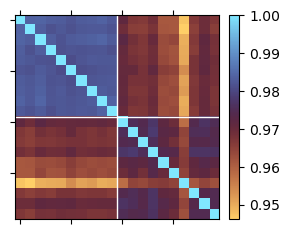

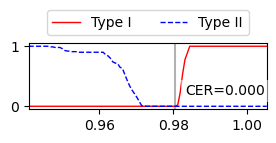

In [36]:
group_baseline = [value for value in data['M-SP-PITCH-V2-0004-0.3'] if value['info']['meta'] == 'hot-mesh-hot-serial-5-25-07-02-01-p0.3'][:10]
group_hot = [value for value in data['M-SP-PITCH-V2-0005-0.3'] if value['info']['meta'] == 'hot-mesh-hot-serial-5-25-07-02-01-p0.3'][:10]

smooth = None
plot_vector_covar(group_baseline, group_hot, vector_method='norm', distance_method='corr', smooth=smooth, plot_cdf=True, fig_out='hot_mesh', do_lines=True)

## How much do our measurements drift with time?

Two measurement series were taken approximately 2h30 apart. Note that we could not precisely control temperature during this time, meaning some drift due to a degree or two of temperature difference would be expected.

2025-07-02T14:12:06.264Z
2025-07-02T16:44:21.617Z
setting threshold for quantile 0.001
Baseline threshold set at 0.973546

Distribution parameters:
Within class: 0.979±0.00174 min: 0.975 max: 0.983
Cross class: 0.98±0.00134 min: 0.976 max: 0.983

Type 1 error (false alarm rate): 0.001000000000
Type 2 error (missed alarm rate): 0.999998395762
EER: 0.6029850746268657 th: 0.9795569289147479
setting threshold for quantile 0.001
Baseline threshold set at 0.160074

Distribution parameters:
Within class: 0.418±0.0836 min: 0.208 max: 0.539
Cross class: 0.39±0.0899 min: 0.105 max: 0.539

Type 1 error (false alarm rate): 0.001000000000
Type 2 error (missed alarm rate): 0.994771050513
EER: 0.4235294117647059 th: 0.42234734134839336


(<Figure size 300x300 with 2 Axes>,
 <Axes: >,
 <Figure size 300x150 with 1 Axes>,
 <Axes: >)

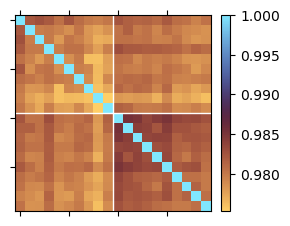

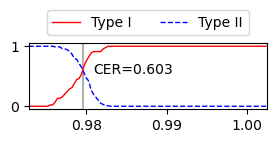

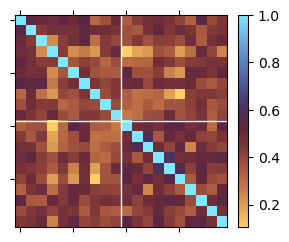

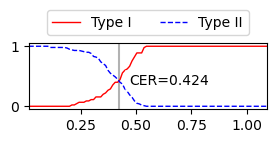

In [37]:
group_a = [value for value in data['M-SP-PITCH-V2-0010-0.3'] if value['info']['meta'] == 'probe-interleave-25-07-02-01-p0.3'][:10]
group_b = [value for entry in data.values() for value in entry if value['info']['meta'] == 'baseline-repeat-25-07-02-02-p0.3']
print(group_a[-1]['info']['timestamp'])
print(group_b[-1]['info']['timestamp'])
plot_vector_covar(group_a, group_b, vector_method='norm', distance_method='corr', plot_cdf=True, fig_out='time_drift', do_lines=True)
plot_vector_covar(group_a, group_b, vector_method='min', distance_method='max', plot_cdf=True, fig_out='time_drift_minmax', do_lines=True)

## Can we distinguish baseline versus modified meshes?

Modifications considered here:
* Shorted A/B traces
* One trace cut open
* Our meshes with probe points for the probing/antenna measurements

short_across_traces 0.3
10 2025-07-07T11:12:08.214Z
10 2025-07-07T11:09:39.478Z
setting threshold for quantile 0.001
Baseline threshold set at 0.222156

Distribution parameters:
Within class: 0.434±0.0686 min: 0.312 max: 0.558
Cross class: -4±0.303 min: -4.75 max: -3.5

Type 1 error (false alarm rate): 0.001000000000
Type 2 error (missed alarm rate): 0.000000000000
EER: 0.0 th: 0.2915482296934595
short_across_traces 0.4
10 2025-07-07T11:24:19.057Z
10 2025-07-07T11:21:55.882Z
setting threshold for quantile 0.001
Baseline threshold set at -0.044841

Distribution parameters:
Within class: 0.263±0.0995 min: -0.0456 max: 0.438
Cross class: -2.6±0.907 min: -4.33 max: -1.5

Type 1 error (false alarm rate): 0.001000000000
Type 2 error (missed alarm rate): 0.002394140016
EER: 0.0 th: -0.08129093490444816
open 0.3
10 2025-07-07T11:12:08.214Z
10 2025-07-07T11:14:58.826Z
setting threshold for quantile 0.001
Baseline threshold set at 0.222156

Distribution parameters:
Within class: 0.434±0.0686 min

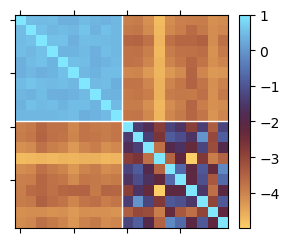

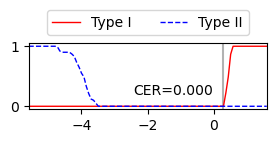

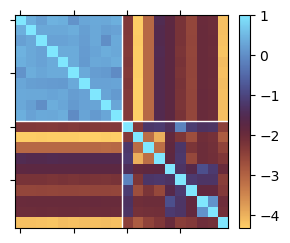

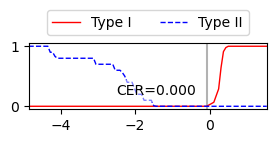

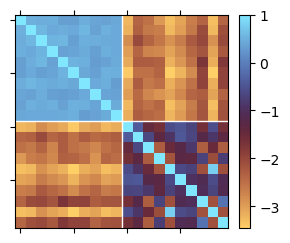

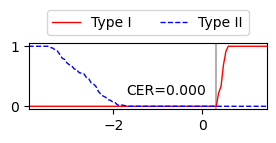

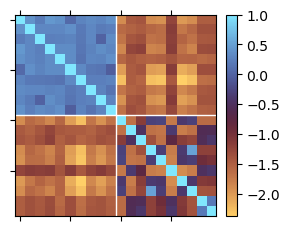

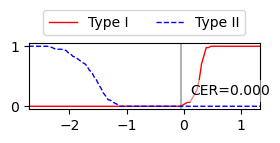

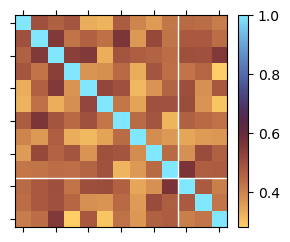

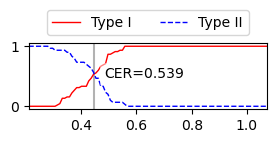

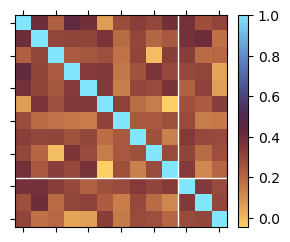

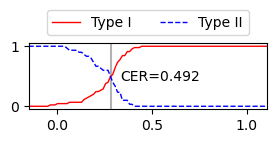

In [38]:
for mod in ['short_across_traces', 'open', 'probe_points']:
    for pitch in ['0.3', '0.4']:
        print(f'{mod} {pitch}')
        group_a = [value for value in data_runs[f'simple-attack-25-07-07-01-p{pitch}'] if not value['info']['mods']]
        group_b = [value for value in data_runs[f'simple-attack-25-07-07-01-p{pitch}'] if mod in value['info']['mods']]
        if not group_a or not group_b:
            print('(skip)')
            continue
        
        print(len(group_a), group_a[-1]['info']['timestamp'])
        print(len(group_b), group_b[-1]['info']['timestamp'])
        plot_vector_covar(group_a, group_b, vector_method='min', distance_method='max', plot_cdf=True, fig_out=f'{mod}_p{pitch}', do_lines=True)

## Can we distinguish baseline versus patched traces?

Patches are done using small wire loops 3~5 mm in length. This should be quite difficult.

10 2025-07-09T14:51:57.358Z
10 2025-07-09T14:55:25.582Z
setting threshold for quantile 0.001
Baseline threshold set at 0.983033

Distribution parameters:
Within class: 0.987±0.00119 min: 0.984 max: 0.989
Cross class: 0.95±0.0828 min: 0.699 max: 0.983

Type 1 error (false alarm rate): 0.001000000000
Type 2 error (missed alarm rate): 0.346782600833
EER: 0.07787610619469026 th: 0.9830982899836443
setting threshold for quantile 0.001
Baseline threshold set at 0.313374

Distribution parameters:
Within class: 0.514±0.0649 min: 0.315 max: 0.628
Cross class: -0.0978±0.813 min: -2.45 max: 0.523

Type 1 error (false alarm rate): 0.001000000000
Type 2 error (missed alarm rate): 0.306497894003
EER: 0.12000000000000001 th: 0.4415850066114029


(<Figure size 300x300 with 2 Axes>,
 <Axes: >,
 <Figure size 300x150 with 1 Axes>,
 <Axes: >)

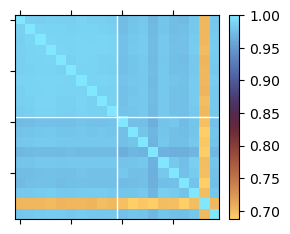

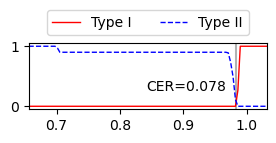

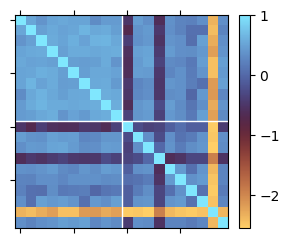

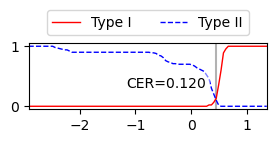

In [57]:
group_a = [value for value in data_runs[f'patch-attack-25-07-09-01-p0.3'] if not value['info']['mods']]
group_b = [value for value in data_runs[f'patch-attack-25-07-09-01-p0.3'] if 'loop_patch' in value['info']['mods']]

print(len(group_a), group_a[-1]['info']['timestamp'])
print(len(group_b), group_b[-1]['info']['timestamp'])
plot_vector_covar(group_a, group_b, plot_cdf=True, fig_out='patch_p0.3', do_lines=True)
plot_vector_covar(group_a, group_b, vector_method='min', distance_method='max', plot_cdf=True, fig_out='patch_p0.3_minmax', do_lines=True)

## Can we distinguish baseline versus a soldering iron touching one trace in one point?

The soldering iron was touching the trace across the whole measurement series. The iron affects trace biasing, and thus in the moment the trace is touched/released there would be sharp steps in the measurements.

10 2025-07-08T18:27:52.545Z
10 2025-07-08T18:26:12.449Z
setting threshold for quantile 0.001
Baseline threshold set at 0.984799

Distribution parameters:
Within class: 0.986±0.000537 min: 0.985 max: 0.987
Cross class: 0.936±0.00569 min: 0.923 max: 0.944

Type 1 error (false alarm rate): 0.001000000000
Type 2 error (missed alarm rate): 0.000000000000
EER: 0.0 th: 0.9842857435867194
setting threshold for quantile 0.001
Baseline threshold set at 0.414871

Distribution parameters:
Within class: 0.54±0.0404 min: 0.437 max: 0.629
Cross class: -0.839±0.328 min: -1.41 max: -0.377

Type 1 error (false alarm rate): 0.001000000000
Type 2 error (missed alarm rate): 0.000065988548
EER: 0.0 th: 0.4237879413778003


(<Figure size 300x300 with 2 Axes>,
 <Axes: >,
 <Figure size 300x150 with 1 Axes>,
 <Axes: >)

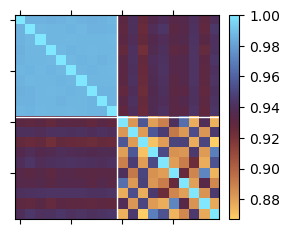

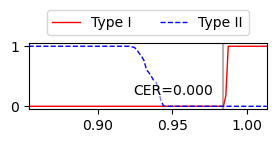

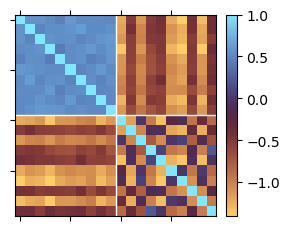

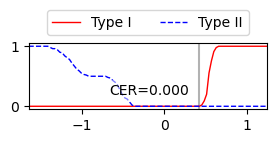

In [40]:
group_a = [value for value in data_runs[f'attack-soldering-iron-25-07-08-01-p0.3'] if not value['info']['mods']][-10:]
group_b = [value for value in data_runs[f'attack-soldering-iron-25-07-08-01-p0.3'] if 'probe_points' in value['info']['mods']][-10:]

print(len(group_a), group_a[-1]['info']['timestamp'])
print(len(group_b), group_b[-1]['info']['timestamp'])
plot_vector_covar(group_a, group_b, plot_cdf=True, fig_out='soldering_p0.3', do_lines=True)
plot_vector_covar(group_a, group_b, vector_method='min', distance_method='max', plot_cdf=True, fig_out='soldering_p0.3_minmax', do_lines=True)

## Can we distinguish baseline versus a trace with a 30 mm wire solderted to one point?

The wire is standing up diagonally from the board to emulate soldering.

10 2025-07-08T18:27:52.545Z
10 2025-07-08T18:42:06.356Z
setting threshold for quantile 0.001
Baseline threshold set at 0.984799

Distribution parameters:
Within class: 0.986±0.000537 min: 0.985 max: 0.987
Cross class: 0.979±0.00436 min: 0.971 max: 0.985

Type 1 error (false alarm rate): 0.001000000000
Type 2 error (missed alarm rate): 0.095942766287
EER: 0.006896551724137931 th: 0.9849765969646525
setting threshold for quantile 0.001
Baseline threshold set at 0.414871

Distribution parameters:
Within class: 0.54±0.0404 min: 0.437 max: 0.629
Cross class: 0.281±0.191 min: -0.253 max: 0.534

Type 1 error (false alarm rate): 0.001000000000
Type 2 error (missed alarm rate): 0.240736936325
EER: 0.11071428571428572 th: 0.4874180862770304


(<Figure size 300x300 with 2 Axes>,
 <Axes: >,
 <Figure size 300x150 with 1 Axes>,
 <Axes: >)

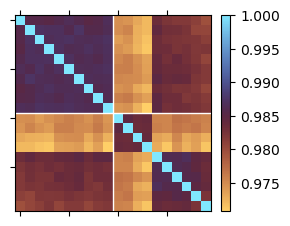

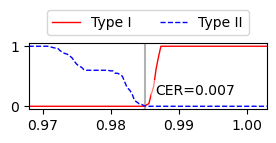

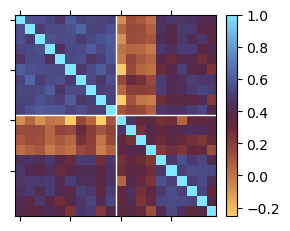

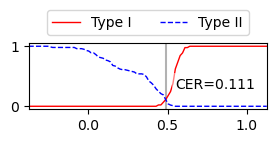

In [41]:
group_a = [value for value in data_runs[f'attack-soldering-iron-25-07-08-01-p0.3'] if not value['info']['mods']][-10:]
group_b = [value for value in data_runs[f'attack-soldering-wire-25-07-08-01-p0.3'] if 'probe_points' in value['info']['mods']][-10:]

print(len(group_a), group_a[-1]['info']['timestamp'])
print(len(group_b), group_b[-1]['info']['timestamp'])
plot_vector_covar(group_a, group_b, plot_cdf=True, fig_out='antenna_wire_30mm_p0.3', do_lines=True)
plot_vector_covar(group_a, group_b, vector_method='min', distance_method='max', plot_cdf=True, fig_out='antenna_wire_30mm_p0.3_minmax', do_lines=True)

## Environment sensitivity (RF/EMI): Can we distinguish traces taken in different environments?

Pitch 0.3
10 2025-07-08T09:06:33.827Z
40 2025-07-09T11:02:20.361Z
setting threshold for quantile 0.001
Baseline threshold set at 0.277766

Distribution parameters:
Within class: 0.494±0.0699 min: 0.261 max: 0.613
Cross class: 0.456±0.0831 min: 0.159 max: 0.616

Type 1 error (false alarm rate): 0.001000000000
Type 2 error (missed alarm rate): 0.983801298679
EER: 0.43344155844155846 th: 0.4819268680028571
setting threshold for quantile 0.001
Baseline threshold set at 0.981947

Distribution parameters:
Within class: 0.985±0.00113 min: 0.983 max: 0.988
Cross class: 0.983±0.00197 min: 0.979 max: 0.988

Type 1 error (false alarm rate): 0.001000000000
Type 2 error (missed alarm rate): 0.782491864956
EER: 0.2542372881355932 th: 0.9847138262468288
Pitch 0.4
10 2025-07-08T09:07:51.026Z
40 2025-07-09T11:04:11.189Z
setting threshold for quantile 0.001
Baseline threshold set at -0.224840

Distribution parameters:
Within class: 0.224±0.145 min: -0.362 max: 0.441
Cross class: 0.267±0.113 min: -0.268 

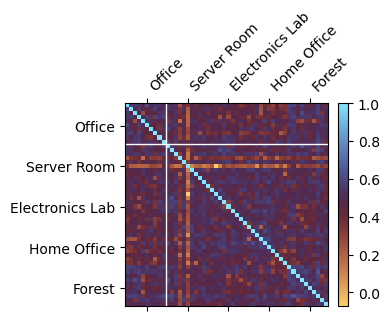

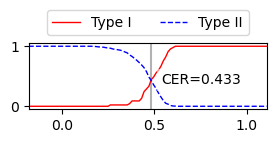

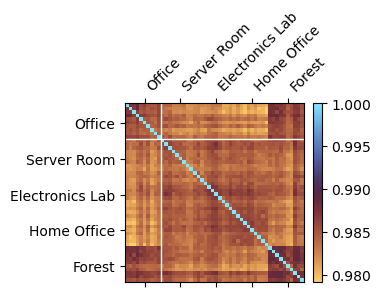

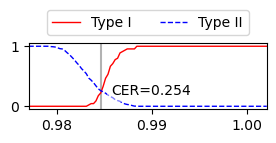

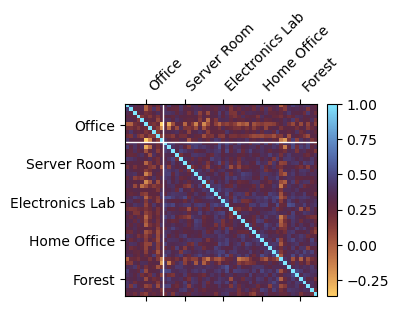

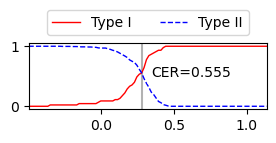

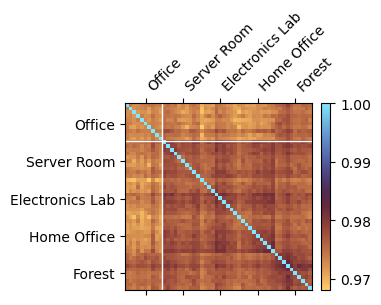

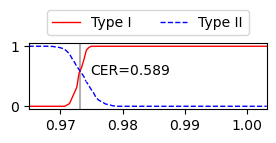

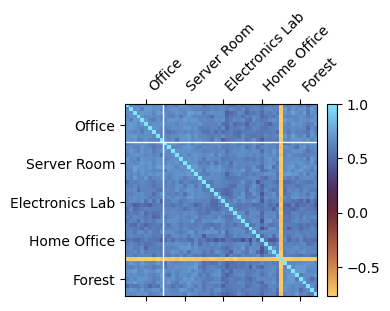

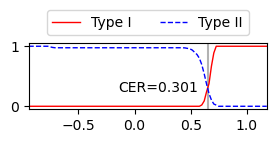

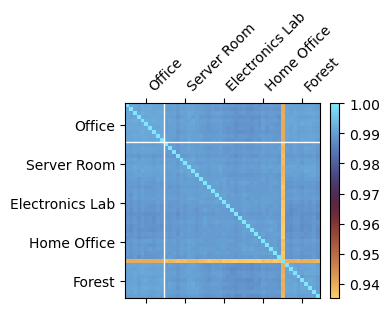

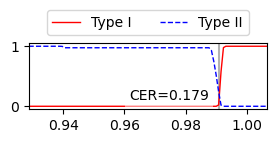

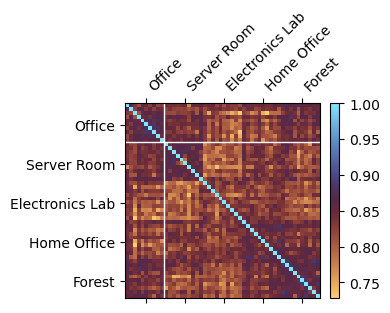

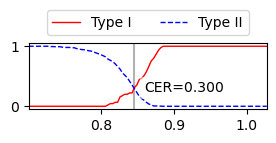

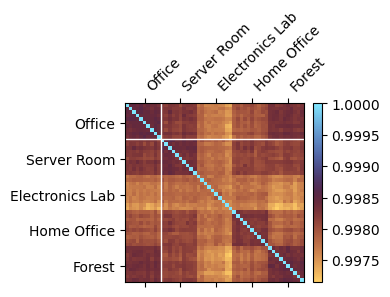

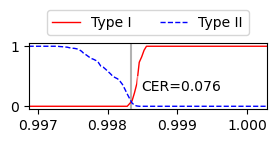

In [42]:
for pitch in ['0.3', '0.4', '0.6', '1.0']:
    print(f'Pitch {pitch}')
    # use office environment as baseline
    environments = [
        '25-07-08-01-serverroom-p14s',
        '25-07-08-01-electronicslab-p14s',
        '25-07-08-01-homeoffice-desktop',
        '25-07-09-01-forest-x1c',
    ]
    batchlabels = ([5, 15, 25, 35, 45], ['Office', 'Server Room', 'Electronics Lab', 'Home Office', 'Forest'])
    group_a = [value for value in data_runs[f'environment-25-07-08-01-office-p14s-p{pitch}'] if not value['info']['mods']]
    group_b = [value for env in environments for value in data_runs[f'environment-{env}-p{pitch}'] if not value['info']['mods']]
    if not group_a or not group_b:
        print('(skip)')
        continue
    
    print(len(group_a), group_a[-1]['info']['timestamp'])
    print(len(group_b), group_b[-1]['info']['timestamp'])
    plot_vector_covar(group_a, group_b, vector_method='min', distance_method='max', plot_cdf=True, fig_out=f'environment_p{pitch}_minmax', do_lines=True, batchlabels=batchlabels, figsize=(4, 4))
    plot_vector_covar(group_a, group_b, plot_cdf=True, fig_out=f'environment_p{pitch}', do_lines=True, batchlabels=batchlabels, figsize=(4, 4))

### Compare environmental effects against an attack

Repeat the above measurement, but compare to the "scope probe" attack run for scale.

Pitch 0.3
50 2025-07-09T11:02:20.361Z
10 2025-07-02T14:10:30.806Z
setting threshold for quantile 0.001
Baseline threshold set at 0.187119

Distribution parameters:
Within class: 0.464±0.0896 min: -0.0726 max: 0.636
Cross class: -0.604±0.225 min: -1.22 max: -0.205

Type 1 error (false alarm rate): 0.001000000000
Type 2 error (missed alarm rate): 0.000217549887
EER: 0.0 th: -0.09584650645280735
setting threshold for quantile 0.001
Baseline threshold set at 0.978854

Distribution parameters:
Within class: 0.984±0.00173 min: 0.979 max: 0.989
Cross class: 0.944±0.00648 min: 0.928 max: 0.957

Type 1 error (false alarm rate): 0.001000000000
Type 2 error (missed alarm rate): 0.000000045601
EER: 0.0 th: 0.9781386054550003


(<Figure size 400x400 with 2 Axes>,
 <Axes: >,
 <Figure size 300x150 with 1 Axes>,
 <Axes: >)

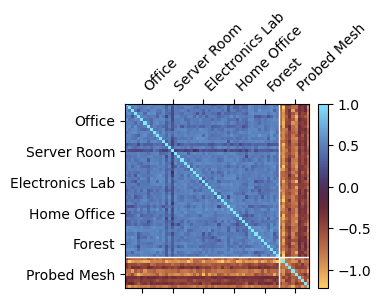

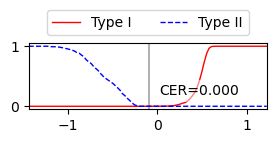

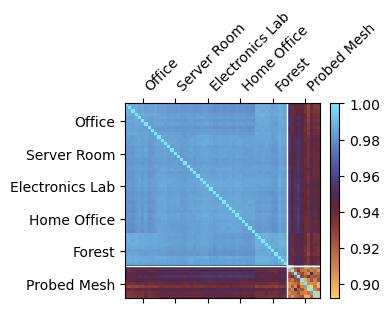

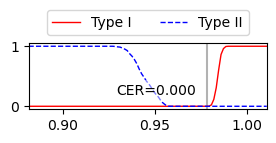

In [43]:
# Same data as above, but add scope probe run for scale
pitch = '0.3'
print(f'Pitch {pitch}')

environments = [
    '25-07-08-01-office-p14s',
    '25-07-08-01-serverroom-p14s',
    '25-07-08-01-electronicslab-p14s',
    '25-07-08-01-homeoffice-desktop',
    '25-07-09-01-forest-x1c',
]
batchlabels = ([5, 15, 25, 35, 45, 55], ['Office', 'Server Room', 'Electronics Lab', 'Home Office', 'Forest', 'Probed Mesh'])
group_a = [value for env in environments for value in data_runs[f'environment-{env}-p{pitch}'] if not value['info']['mods']]
group_b = [value for entries in data.values() for value in entries if value['info']['meta'] == 'probe-interleave-25-07-02-01-p0.3' and 'probe_points' in value['info']['mods']][:10]

print(len(group_a), group_a[-1]['info']['timestamp'])
print(len(group_b), group_b[-1]['info']['timestamp'])
plot_vector_covar(group_a, group_b, vector_method='min', distance_method='max', plot_cdf=True, fig_out=f'environment_ref_probe_p{pitch}_minmax', do_lines=True, batchlabels=batchlabels, figsize=(4, 4))
plot_vector_covar(group_a, group_b, plot_cdf=True, fig_out=f'environment_ref_probe_p{pitch}', do_lines=True, batchlabels=batchlabels, figsize=(4, 4))

### Compare environmental effects against the hot mesh scenario

Repeat the above measurement, but compare to the "hot mesh" run for scale.

Pitch 0.3
50 2025-07-09T11:02:20.361Z
10 2025-07-02T15:01:50.886Z
setting threshold for quantile 0.001
Baseline threshold set at 0.187119

Distribution parameters:
Within class: 0.464±0.0896 min: -0.0726 max: 0.636
Cross class: -0.214±0.125 min: -0.643 max: 0.089

Type 1 error (false alarm rate): 0.001000000000
Type 2 error (missed alarm rate): 0.000645153336
EER: 0.0016326530612244899 th: 0.08096889595885896
setting threshold for quantile 0.001
Baseline threshold set at 0.978854

Distribution parameters:
Within class: 0.984±0.00173 min: 0.979 max: 0.989
Cross class: 0.971±0.00395 min: 0.956 max: 0.977

Type 1 error (false alarm rate): 0.001000000000
Type 2 error (missed alarm rate): 0.022981796940
EER: 0.0 th: 0.978652829116029


(<Figure size 400x400 with 2 Axes>,
 <Axes: >,
 <Figure size 300x150 with 1 Axes>,
 <Axes: >)

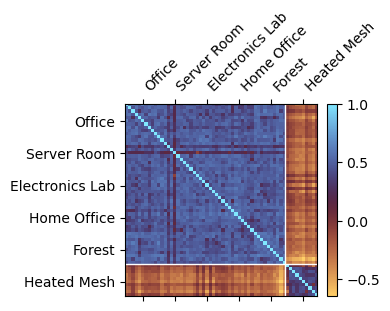

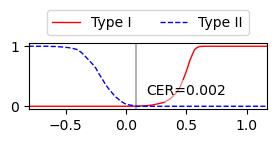

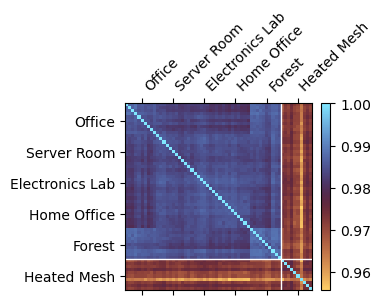

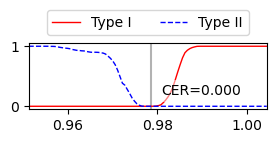

In [44]:
#Same as above, but compare to heated mesh
pitch = '0.3'
print(f'Pitch {pitch}')

environments = [
    '25-07-08-01-office-p14s',
    '25-07-08-01-serverroom-p14s',
    '25-07-08-01-electronicslab-p14s',
    '25-07-08-01-homeoffice-desktop',
    '25-07-09-01-forest-x1c',
]
batchlabels = ([5, 15, 25, 35, 45, 55], ['Office', 'Server Room', 'Electronics Lab', 'Home Office', 'Forest', 'Heated Mesh'])
group_a = [value for env in environments for value in data_runs[f'environment-{env}-p{pitch}'] if not value['info']['mods']]
group_b = [value for value in data['M-SP-PITCH-V2-0005-0.3'] if value['info']['meta'] == 'hot-mesh-hot-serial-5-25-07-02-01-p0.3'][:10]

print(len(group_a), group_a[-1]['info']['timestamp'])
print(len(group_b), group_b[-1]['info']['timestamp'])
plot_vector_covar(group_a, group_b, vector_method='min', distance_method='max', plot_cdf=True, fig_out=f'environment_ref_probe_p{pitch}_minmax', do_lines=True, batchlabels=batchlabels, figsize=(4, 4))
plot_vector_covar(group_a, group_b, plot_cdf=True, fig_out=f'environment_ref_probe_p{pitch}', do_lines=True, batchlabels=batchlabels, figsize=(4, 4))

### Compare environmental effects against the patching attack

Repeat the above measurement, but compare to the "loop patch" attack run for scale.

Pitch 0.3
50 2025-07-09T11:02:20.361Z
10 2025-07-08T17:31:25.244Z
setting threshold for quantile 0.001
Baseline threshold set at 0.187119

Distribution parameters:
Within class: 0.464±0.0896 min: -0.0726 max: 0.636
Cross class: -0.0202±0.79 min: -2.47 max: 0.551

Type 1 error (false alarm rate): 0.001000000000
Type 2 error (missed alarm rate): 0.396483909561
EER: 0.21596401028277637 th: 0.4076621357746832
setting threshold for quantile 0.001
Baseline threshold set at 0.978854

Distribution parameters:
Within class: 0.984±0.00173 min: 0.979 max: 0.989
Cross class: 0.951±0.0824 min: 0.698 max: 0.986

Type 1 error (false alarm rate): 0.001000000000
Type 2 error (missed alarm rate): 0.368705970764
EER: 0.12996884735202494 th: 0.9821635381409752


(<Figure size 400x400 with 2 Axes>,
 <Axes: >,
 <Figure size 300x150 with 1 Axes>,
 <Axes: >)

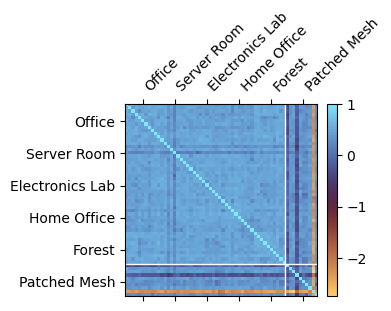

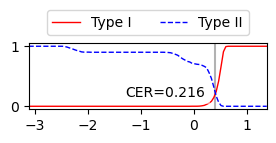

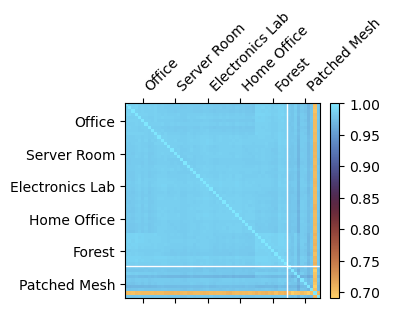

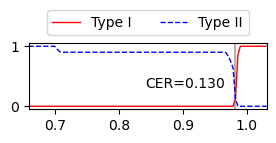

In [45]:
#Same as above, but compare to patched mesh
pitch = '0.3'
print(f'Pitch {pitch}')

environments = [
    '25-07-08-01-office-p14s',
    '25-07-08-01-serverroom-p14s',
    '25-07-08-01-electronicslab-p14s',
    '25-07-08-01-homeoffice-desktop',
    '25-07-09-01-forest-x1c',
]
batchlabels = ([5, 15, 25, 35, 45, 55], ['Office', 'Server Room', 'Electronics Lab', 'Home Office', 'Forest', 'Patched Mesh'])
group_a = [value for env in environments for value in data_runs[f'environment-{env}-p{pitch}'] if not value['info']['mods']]
group_b = [value for value in data_runs[f'simple-attack-25-07-08-01-p0.3'] if 'loop_patch' in value['info']['mods']]

print(len(group_a), group_a[-1]['info']['timestamp'])
print(len(group_b), group_b[-1]['info']['timestamp'])
plot_vector_covar(group_a, group_b, vector_method='min', distance_method='max', plot_cdf=True, fig_out=f'environment_ref_probe_p{pitch}_minmax', do_lines=True, batchlabels=batchlabels, figsize=(4, 4))
plot_vector_covar(group_a, group_b, plot_cdf=True, fig_out=f'environment_ref_probe_p{pitch}', do_lines=True, batchlabels=batchlabels, figsize=(4, 4))

## Repeat baseline vs. looped patch experiment using TDP0604

Let's see if that board is any better than the PI3HDX12211 that we use in the other runs (spoiler: no, it's not).

10 2025-07-09T15:11:08.766Z
10 2025-07-09T15:11:29.146Z
setting threshold for quantile 0.001
Baseline threshold set at 0.995213

Distribution parameters:
Within class: 0.997±0.000417 min: 0.996 max: 0.998
Cross class: 0.972±0.0684 min: 0.765 max: 0.997

Type 1 error (false alarm rate): 0.001000000000
Type 2 error (missed alarm rate): 0.368134993436
EER: 0.37183098591549296 th: 0.9959356111983982
setting threshold for quantile 0.001
Baseline threshold set at 0.676287

Distribution parameters:
Within class: 0.808±0.0426 min: 0.67 max: 0.862
Cross class: 0.493±0.734 min: -1.72 max: 0.859

Type 1 error (false alarm rate): 0.001000000000
Type 2 error (missed alarm rate): 0.401475759067
EER: 0.31320754716981136 th: 0.7944348801630056


(<Figure size 300x300 with 2 Axes>,
 <Axes: >,
 <Figure size 300x150 with 1 Axes>,
 <Axes: >)

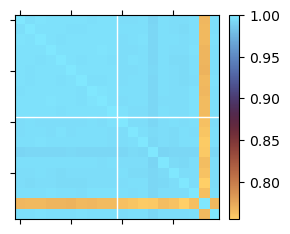

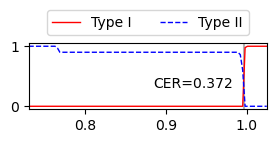

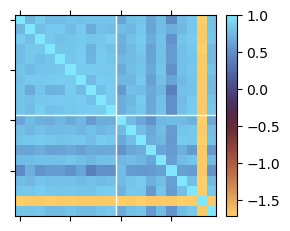

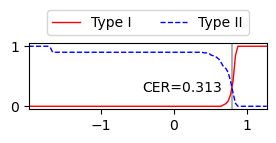

In [56]:
# Can we distinguish baseline versus patched traces? Patches are done using small wire loops 3~5 mm in length.
# Here: using TDP0604
group_a = [value for value in data_runs[f'patch-attack-25-07-09-02-p0.3'] if not value['info']['mods']][:10]
group_b = [value for value in data_runs[f'patch-attack-25-07-09-02-p0.3'] if 'loop_patch' in value['info']['mods']]

print(len(group_a), group_a[-1]['info']['timestamp'])
print(len(group_b), group_b[-1]['info']['timestamp'])
plot_vector_covar(group_a, group_b, plot_cdf=True, fig_out='patch_tdp0604_p0.3', do_lines=True)
plot_vector_covar(group_a, group_b, vector_method='min', distance_method='max', plot_cdf=True, fig_out='patch_tdp0604_p0.3_minmax', do_lines=True)

## Repeat looped patch experiment with multiple runs per sample

10 runs per loop sample, and 20 baseline runs, 10 before and 10 after the patch samples

{'SP-PITCH-V2-0057', 'SP-PITCH-V2-0061', 'SP-PITCH-V2-0063', 'SP-PITCH-V2-0062', 'SP-PITCH-V2-0058', 'SP-PITCH-V2-0060', 'SP-PITCH-V2-0065'}
20 2025-07-09T17:39:02.553Z
70 2025-07-09T17:37:40.678Z
setting threshold for quantile 0.001
Baseline threshold set at 0.991727

Distribution parameters:
Within class: 0.997±0.00157 min: 0.993 max: 0.999
Cross class: 0.994±0.00348 min: 0.982 max: 0.998

Type 1 error (false alarm rate): 0.001000000000
Type 2 error (missed alarm rate): 0.715256625096
EER: 0.33910524621821697 th: 0.9956765300747624
setting threshold for quantile 0.001
Baseline threshold set at 0.470057

Distribution parameters:
Within class: 0.633±0.0528 min: 0.449 max: 0.77
Cross class: 0.473±0.101 min: 0.0629 max: 0.711

Type 1 error (false alarm rate): 0.001000000000
Type 2 error (missed alarm rate): 0.510969730299
EER: 0.14564546016059293 th: 0.578163021102501


(<Figure size 500x500 with 2 Axes>,
 <Axes: >,
 <Figure size 300x150 with 1 Axes>,
 <Axes: >)

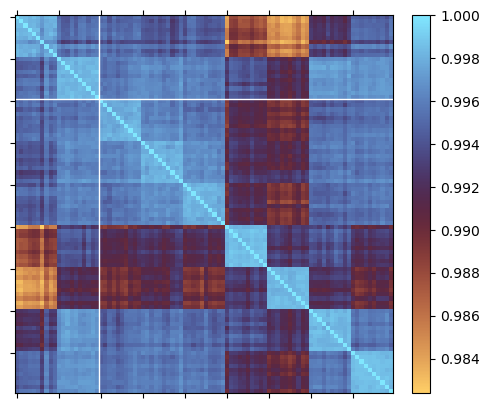

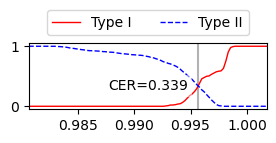

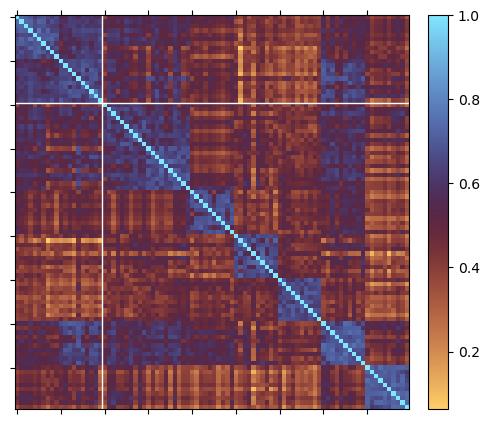

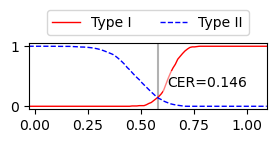

In [117]:
group_a = [value for value in data_runs[f'attack-repeat-25-07-09-01-p0.3'] if not value['info']['mods']]
# Exclude mesh 56 as its response is easily distinguished by min/max, making it light up very bright in the plot and swamping out the colorscheme for everything else.
# We also specifically did not measure that one sample that got a hidden short during modification, since that's also too easy.
group_b = [value for value in data_runs[f'attack-repeat-25-07-09-01-p0.3'] if 'loop_patch' in value['info']['mods'] and value['info']['serial'] != 56]

print(set(x['info']['specimen'] for x in group_b))
print(len(group_a), group_a[-1]['info']['timestamp'])
print(len(group_b), group_b[-1]['info']['timestamp'])

plot_vector_covar(group_a, group_b, plot_cdf=True, fig_out='patch_repeat_p0.3', do_lines=True, figsize=(5, 5), smooth=1e-7)
plot_vector_covar(group_a, group_b, vector_method='min', distance_method='max', plot_cdf=True, fig_out='patch_repeat_p0.3_minmax', do_lines=True, figsize=(5, 5), smooth=1e-9)